# Pengembangan *Clinical Decision Support System* Berbasis XGBoost dengan XAI untuk Deteksi Dini Risiko Diabetes Melitus

**Notebook eksperimen utama (`Models.ipynb`).** Seluruh angka pada laporan dan slide berasal dari keluaran sel-sel di bawah ini.

**Prinsip desain anti-*leakage*:**
1. *Test set* 20% disisihkan **di awal** dan tidak pernah disentuh oleh imputasi, *resampling*, seleksi fitur, *tuning*, kalibrasi, maupun pemilihan ambang.
2. Semua operasi yang *belajar dari data* (imputasi median, *scaling* untuk jarak SMOTE, *resampling*, seleksi fitur SHAP, model) berada di dalam `imblearn.pipeline.Pipeline` dan di-*fit* ulang pada setiap *fold*. *Encoding* kategorikal memakai kamus tetap (tidak dipelajari dari data) sehingga aman dilakukan sebelum *split*.
3. Pemisahan bersifat ***group-aware*** (`StratifiedGroupKFold`): salinan/duplikat dari rekaman yang sama tidak pernah berada di sisi latih dan uji sekaligus.

| Bagian | Isi |
|---|---|
| 1 | Setup, konfigurasi, reproduktibilitas |
| 2 | Pemuatan data dan audit kualitas (termasuk temuan replikasi blok pada Diabetes 2019) |
| 3 | Pembersihan data dan *encoding* deterministik per file CSV |
| 4 | Protokol pemisahan anti-*leakage* dan audit kebocoran |
| 5 | Komponen pipeline: *type-aware resampler*, XGBoost sensitif-biaya, seleksi fitur SHAP, kalibrator |
| 6 | Mesin evaluasi: prediksi *out-of-fold* (OOF), ambang dan kalibrasi *cross-fitted*, metrik klinis |
| 7 | Studi ablasi S0–S4 (+ kontrol S2′) dengan *tuning* Optuna (TPE) |
| 8 | Analisis kalibrasi probabilitas (H3) |
| 9 | Analisis seleksi fitur berbasis SHAP (H2) |
| 10 | XAI: SHAP global dan lokal, konsistensi klinis (H4) |
| 11 | Sensitivitas protokol: *split* acak gaya literatur vs *leakage-free*; deduplikasi |
| 12 | Komparasi dengan lima paper rujukan |
| 13 | Lapisan keputusan CDSS: stratifikasi risiko, ekspor artefak, simulasi pasien baru |
| 14 | Ringkasan uji hipotesis H1–H4 |

**Cara menjalankan.** Letakkan ketiga file CSV di folder notebook (atau `./data/`, atau setel variabel lingkungan `DATA_DIR`), lalu jalankan semua sel. Eksekusi penuh ±16 menit pada CPU 2 inti (BRFSS mendominasi). Setel `CDSS_FAST=1` untuk uji cepat (subsampel dan trial sedikit). Setelah selesai, prototipe CDSS dapat dijalankan dengan `streamlit run cdss_app.py`.

## 1. Setup dan Konfigurasi

In [1]:
import importlib.util, subprocess, sys, warnings
warnings.filterwarnings('ignore')
_need = {'xgboost': 'xgboost', 'shap': 'shap', 'optuna': 'optuna', 'imblearn': 'imbalanced-learn'}
_missing = [pkg for mod, pkg in _need.items() if importlib.util.find_spec(mod) is None]
if _missing:   # instalasi otomatis sekali saja (mis. di Google Colab)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *_missing])
import os, json, time, platform
from pathlib import Path
from dataclasses import dataclass, field
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from scipy import stats
import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (confusion_matrix, roc_auc_score, average_precision_score, brier_score_loss,
                             f1_score, roc_curve, precision_recall_curve)
import imblearn
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC, BorderlineSMOTE, SMOTE
import xgboost as xgb
import shap
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 220)
pd.set_option('display.float_format', lambda v: f'{v:.4f}')
try:
    display
except NameError:          # bila dijalankan sebagai skrip biasa
    display = print

SEED = 42
np.random.seed(SEED)
FAST_MODE = os.environ.get('CDSS_FAST', '0') == '1'
N_JOBS = os.cpu_count() or 2
TEST_SIZE = 0.20                     # Stratified 80:20 (group-aware)
N_FOLDS = 3 if FAST_MODE else 10     # 10-fold stratified (group-aware) CV pada data latih
F_BETA = 2.0                         # ambang keputusan dipilih dengan F2 → recall berbobot 4× presisi (menekan FN)
TIER_SENS = 0.95                     # batas Low→Moderate: sensitivitas OOF ≥ 95% (zona rule-out)
TIER_SPEC = 0.90                     # batas Moderate→High: spesifisitas OOF ≥ 90% (zona rule-in)
SHAP_CUM = 0.90                      # S3: fitur dipertahankan hingga kumulatif ≥ 90% total mean|SHAP|
OPTUNA_CFG = {
    'diabetes2019': dict(n_trials=6 if FAST_MODE else 60, inner_folds=3 if FAST_MODE else 5, max_rows=None),
    'pima':         dict(n_trials=6 if FAST_MODE else 60, inner_folds=3 if FAST_MODE else 5, max_rows=None),
    'brfss':        dict(n_trials=4 if FAST_MODE else 25, inner_folds=3, max_rows=6_000 if FAST_MODE else 40_000),
}
SELECTOR_CFG = {'diabetes2019': {}, 'pima': {},
                'brfss': dict(max_rows=20_000, shap_rows=3_000)}   # BRFSS: subsampel internal agar seleksi cepat
BRFSS_MAX_ROWS = 15_000 if FAST_MODE else None                     # hanya untuk uji cepat
N_BOOT = 200 if FAST_MODE else 1000

OUT = Path('outputs'); FIG = OUT / 'figures'; ART = OUT / 'cdss'
for p in (OUT, FIG, ART):
    p.mkdir(parents=True, exist_ok=True)

# Palet kategorikal tervalidasi (urutan tetap; tiga slot pertama lolos uji buta warna untuk semua pasangan)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
TEXT, TEXT2, GRID, SURF = '#0b0b0b', '#52514e', '#e5e4df', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF, 'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': TEXT2, 'xtick.color': TEXT2, 'ytick.color': TEXT2, 'text.color': TEXT, 'axes.titlecolor': TEXT,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.prop_cycle': cycler(color=PALETTE),
    'font.size': 10, 'axes.titlesize': 11, 'legend.frameon': False, 'figure.dpi': 100, 'savefig.dpi': 150,
    'savefig.bbox': 'tight', 'lines.linewidth': 2})

def savefig(fig, name):
    fig.savefig(FIG / f'{name}.png')
    plt.show()

T_START = time.time()
print(f'Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | '
      f'imbalanced-learn {imblearn.__version__} | xgboost {xgb.__version__} | shap {shap.__version__} | optuna {optuna.__version__}')
print(f'FAST_MODE={FAST_MODE} | N_FOLDS={N_FOLDS} | CPU={N_JOBS}')

Python 3.14.10 | numpy 2.5.5 | pandas 3.1.1 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2 | xgboost 3.4.1 | shap 0.54.1 | optuna 5.1.0
FAST_MODE=False | N_FOLDS=10 | CPU=16


## 2. Pemuatan Data dan Audit Kualitas

Audit dilakukan pada data mentah sebelum pembersihan apa pun, untuk mendokumentasikan anomali yang harus ditangani.

In [2]:
FILES = {'diabetes2019': 'diabetes_dataset__2019.csv', 'pima': 'pima_indians_diabetes.csv',
         'brfss': 'BRFSS2015_Diabetes_Binary_NoPrediabetes.csv'}
TARGET = {'diabetes2019': 'Diabetic', 'pima': 'Outcome', 'brfss': 'Diabetes_Binary'}
TITLE = {'diabetes2019': 'Diabetes 2019', 'pima': 'PIMA', 'brfss': 'BRFSS 2015'}
DS_COLOR = {'diabetes2019': PALETTE[0], 'pima': PALETTE[1], 'brfss': PALETTE[2]}

def find_file(name):
    for d in [os.environ.get('DATA_DIR', ''), '.', 'data', '..', '/content', '/content/data', '/content/drive/MyDrive']:
        p = (Path(d) / name) if d else Path(name)
        if p.exists():
            return p
    raise FileNotFoundError(f'{name} tidak ditemukan. Letakkan file di folder notebook atau setel DATA_DIR.')

RAW = {k: pd.read_csv(find_file(f)) for k, f in FILES.items()}

def audit_row(key, df):
    t = TARGET[key]; X = df.drop(columns=t)
    return {'Dataset': TITLE[key], 'Baris': len(df), 'Fitur': X.shape[1],
            'Distribusi label mentah': {repr(k): int(v) for k, v in df[t].value_counts(dropna=False).items()},
            'Sel hilang': int(df.isna().sum().sum()), 'Duplikat baris identik': int(df.duplicated().sum()),
            'Duplikat vektor fitur': int(X.duplicated().sum())}

display(pd.DataFrame([audit_row(k, d) for k, d in RAW.items()]))
for k, d in RAW.items():
    m = d.isna().sum(); m = m[m > 0]
    print(f'{TITLE[k]:>13}: nilai hilang per kolom → {m.to_dict() if len(m) else "tidak ada"}')
PIMA_ZERO_AS_NAN = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print('         PIMA: nilai 0 non-fisiologis →', (RAW['pima'][PIMA_ZERO_AS_NAN] == 0).sum().to_dict())
d = RAW['diabetes2019']
for c in ['Diabetic', 'BPLevel', 'RegularMedicine', 'Pdiabetes']:
    print(f'Diabetes 2019 · {c}: {d[c].value_counts(dropna=False).to_dict()}')

,Dataset,Baris,Fitur,Distribusi label mentah,Sel hilang,Duplikat baris identik,Duplikat vektor fitur
0,Diabetes 2019,952,17,"{''no'': 684, ''yes'': 266, '' no'': 1, 'nan': 1}",48,622,642
1,PIMA,768,8,"{'0': 500, '1': 268}",0,0,0
2,BRFSS 2015,249049,21,"{'0': 213703, '1': 35346}",0,23897,25433


Diabetes 2019: nilai hilang per kolom → {'BMI': 4, 'Pregancies': 42, 'Pdiabetes': 1, 'Diabetic': 1}
         PIMA: nilai hilang per kolom → tidak ada
   BRFSS 2015: nilai hilang per kolom → tidak ada
         PIMA: nilai 0 non-fisiologis → {'Glucose': 5, 'BloodPressure': 35, 'SkinThickness': 227, 'Insulin': 374, 'BMI': 11}
Diabetes 2019 · Diabetic: {'no': 684, 'yes': 266, ' no': 1, nan: 1}
Diabetes 2019 · BPLevel: {'normal': 707, 'high': 211, 'low': 25, 'High': 5, 'Low': 3, 'normal ': 1}
Diabetes 2019 · RegularMedicine: {'no': 615, 'yes': 336, 'o': 1}
Diabetes 2019 · Pdiabetes: {'0': 936, 'yes': 14, nan: 1, 'no': 1}


### 2.1 Temuan kritis: Diabetes 2019 tersusun atas empat blok replikasi

Lebih dari 60% baris Diabetes 2019 adalah duplikat persis. Pemindaian *lag* di bawah menguji apakah baris ke-*i* identik dengan baris ke-(*i*+*L*). Jika file terdiri atas blok-blok yang diulang, persentase identik akan memuncak pada kelipatan panjang blok. Konsekuensinya: *split* acak hampir pasti menempatkan salinan pasien uji di data latih, sehingga akurasi mengukur hafalan, bukan generalisasi.

Lag dengan kemiripan tertinggi: 238 → 90.2% pasangan identik; 99.9% berbeda ≤1 fitur. Jumlah baris / lag = 4.00 blok.
Rekaman unik dalam blok pertama: 238 dari 238
Kesesuaian label blok-0 vs blok-b: [0.928, 0.97, 0.975]


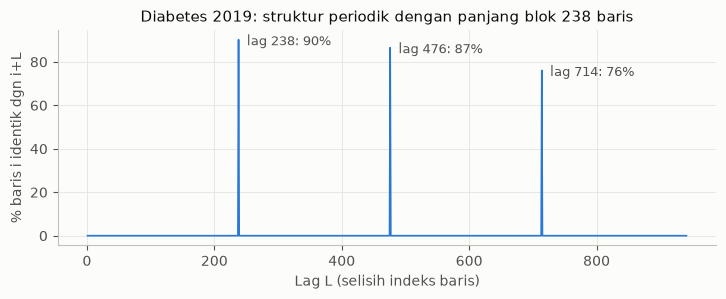

In [3]:
def normalize_strings(df):
    df = df.copy()
    for c in df.columns:
        if df[c].dtype == object or pd.api.types.is_string_dtype(df[c]):
            df[c] = df[c].astype('string').str.strip().str.lower()
    return df

_d19 = normalize_strings(RAW['diabetes2019'])
_A = _d19.drop(columns='Diabetic').astype(str).to_numpy()
lags = np.arange(1, len(_A) - 10)
ident = np.array([(_A[:-L] == _A[L:]).all(axis=1).mean() for L in lags])
PERIOD_2019 = int(lags[np.argmax(ident)])
ham_le1 = ((_A[:-PERIOD_2019] != _A[PERIOD_2019:]).sum(axis=1) <= 1).mean()
print(f'Lag dengan kemiripan tertinggi: {PERIOD_2019} → {ident[PERIOD_2019-1]*100:.1f}% pasangan identik; '
      f'{ham_le1*100:.1f}% berbeda ≤1 fitur. Jumlah baris / lag = {len(_A)/PERIOD_2019:.2f} blok.')
_blk = [_d19.iloc[b*PERIOD_2019:(b+1)*PERIOD_2019].reset_index(drop=True) for b in range(len(_A)//PERIOD_2019)]
print('Rekaman unik dalam blok pertama:', _blk[0].drop(columns='Diabetic').astype(str).drop_duplicates().shape[0], 'dari', PERIOD_2019)
print('Kesesuaian label blok-0 vs blok-b:', [round(float((_blk[0]['Diabetic'] == _blk[b]['Diabetic']).mean()), 3) for b in range(1, len(_blk))])

fig, ax = plt.subplots(figsize=(8.5, 2.8))
ax.plot(lags, ident * 100, color=PALETTE[0], lw=1.2)
for m in (1, 2, 3):
    L = m * PERIOD_2019
    if L <= lags.max():
        ax.annotate(f'lag {L}: {ident[L-1]*100:.0f}%', (L, ident[L-1] * 100), xytext=(6, -4),
                    textcoords='offset points', fontsize=9, color=TEXT2)
ax.set(xlabel='Lag L (selisih indeks baris)', ylabel='% baris i identik dgn i+L',
       title=f'Diabetes 2019: struktur periodik dengan panjang blok {PERIOD_2019} baris')
savefig(fig, 'fig01_periodicity_2019')

## 3. Pembersihan Data dan *Encoding* Deterministik per File CSV

**Diabetes 2019** — (1) normalisasi spasi dan huruf kecil pada semua kolom teks (`' no'`→`'no'`, `'High'`/`'normal '`→`'high'`/`'normal'`); (2) koreksi anomali `RegularMedicine='o'`→`'no'` dan `Pdiabetes='0'`→`'no'`; (3) buang 1 baris target `NaN`; (4) aturan biologis deterministik: laki-laki → `Pregancies=0` dan `Pdiabetes=0` (Pdiabetes ditafsirkan sebagai riwayat diabetes gestasional sesuai daftar atribut kuesioner Tigga & Garg; 13 dari 14 jawaban "yes" berasal dari perempuan); (5) *encoding* ordinal/biner dengan kamus tetap; (6) ID grup = indeks baris mod panjang blok, sehingga keempat salinan satu rekaman menjadi satu grup. Nilai hilang yang tersisa (BMI, Pregancies perempuan) diimputasi **di dalam pipeline**.

**PIMA** — nilai 0 pada `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI` diubah menjadi `NaN` (tidak fisiologis), lalu diimputasi median **di dalam pipeline** (di-*fit* hanya pada *fold* latih). `Pregnancies=0` tetap valid.

**BRFSS 2015** — validasi tipe (semua bilangan bulat) dan rentang kode survei untuk 21 fitur; ID grup = *hash* vektor fitur sehingga baris identik selalu berada di sisi yang sama. Deduplikasi diuji terpisah sebagai analisis sensitivitas (Bagian 11).

In [4]:
YES_NO = {'yes': 1, 'no': 0}
MAPS_2019 = {
    'Age': {'less than 40': 0, '40-49': 1, '50-59': 2, '60 or older': 3},
    'Gender': {'female': 0, 'male': 1},
    'Family_Diabetes': YES_NO, 'highBP': YES_NO,
    'PhysicallyActive': {'none': 0, 'less than half an hr': 1, 'more than half an hr': 2, 'one hr or more': 3},
    'Smoking': YES_NO, 'Alcohol': YES_NO, 'RegularMedicine': YES_NO,
    'JunkFood': {'occasionally': 0, 'often': 1, 'very often': 2, 'always': 3},
    'Stress': {'not at all': 0, 'sometimes': 1, 'very often': 2, 'always': 3},
    'BPLevel': {'low': 0, 'normal': 1, 'high': 2},
    'Pdiabetes': YES_NO, 'UriationFreq': {'not much': 0, 'quite often': 1},
}
ORDER_2019 = ['Age', 'Gender_Male', 'Family_Diabetes', 'highBP', 'PhysicallyActive', 'BMI', 'Smoking', 'Alcohol', 'Sleep',
              'SoundSleep', 'RegularMedicine', 'JunkFood', 'Stress', 'BPLevel', 'Pregancies', 'Pdiabetes', 'UriationFreq']

def encode_2019(df):
    """Encoding deterministik (kamus tetap, tidak dipelajari dari data) → aman sebelum split."""
    X = pd.DataFrame({c: df[c].map(m) for c, m in MAPS_2019.items()}).rename(columns={'Gender': 'Gender_Male'})
    for c in ['BMI', 'Sleep', 'SoundSleep', 'Pregancies']:
        X[c] = pd.to_numeric(df[c], errors='coerce')
    male = X['Gender_Male'] == 1
    X.loc[male, 'Pregancies'] = 0.0        # aturan biologis
    X.loc[male, 'Pdiabetes'] = 0.0         # DM gestasional tidak mungkin pada laki-laki
    return X[ORDER_2019].astype(float)

def clean_diabetes2019(raw, period):
    log = {}
    df = normalize_strings(raw)
    df['base_id'] = np.arange(len(df)) % period
    log["Diabetic ' no' → 'no'"] = int((raw['Diabetic'].astype('string') == ' no').sum())
    log['BPLevel kapital/spasi dinormalisasi'] = int((raw['BPLevel'].astype('string') != df['BPLevel']).sum())
    log["RegularMedicine 'o' → 'no'"] = int((df['RegularMedicine'] == 'o').sum())
    log["Pdiabetes '0' → 'no'"] = int((df['Pdiabetes'] == '0').sum())
    df['RegularMedicine'] = df['RegularMedicine'].replace({'o': 'no'})
    df['Pdiabetes'] = df['Pdiabetes'].replace({'0': 'no'})
    log['Baris target NaN dibuang'] = int(df['Diabetic'].isna().sum())
    df = df[df['Diabetic'].notna()].reset_index(drop=True)
    male = df['Gender'] == 'male'
    preg = pd.to_numeric(df['Pregancies'], errors='coerce')
    log['Pregancies laki-laki NaN → 0'] = int((male & preg.isna()).sum())
    log['Pregancies laki-laki >0 → 0 (anomali)'] = int((male & (preg > 0)).sum())
    log['Pdiabetes laki-laki yes/NaN → 0'] = int((male & df['Pdiabetes'].fillna('NA').ne('no')).sum())
    X = encode_2019(df)
    unmapped = {c: int((df[c].notna() & X[c if c != 'Gender' else 'Gender_Male'].isna()).sum()) for c in MAPS_2019}
    assert sum(unmapped.values()) == 0, f'Kategori tak terpetakan: {unmapped}'
    y = df['Diabetic'].map(YES_NO).astype(int).rename('y')
    return X, y, df['base_id'].to_numpy(), log

def clean_pima(raw):
    X = raw.drop(columns='Outcome').astype(float)
    log = {f'{c}: 0 → NaN': int((X[c] == 0).sum()) for c in PIMA_ZERO_AS_NAN}
    X[PIMA_ZERO_AS_NAN] = X[PIMA_ZERO_AS_NAN].replace(0, np.nan)
    return X, raw['Outcome'].astype(int).rename('y'), np.arange(len(X)), log

BRFSS_BINARY = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits',
                'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
BRFSS_RANGES = {**{c: (0, 1) for c in BRFSS_BINARY}, 'BMI': (12, 98), 'GenHlth': (1, 5), 'MentHlth': (0, 30),
                'PhysHlth': (0, 30), 'Age': (1, 13), 'Education': (1, 6), 'Income': (1, 8)}

def clean_brfss(raw, dedup=False, max_rows=None, seed=SEED):
    df = raw.copy()
    X0 = df.drop(columns='Diabetes_Binary')
    assert np.allclose(X0.to_numpy() % 1, 0), 'BRFSS: semua fitur harus bernilai bilangan bulat'
    bad = {c: int(((X0[c] < lo) | (X0[c] > hi)).sum()) for c, (lo, hi) in BRFSS_RANGES.items()}
    assert sum(bad.values()) == 0, f'Nilai di luar rentang kode survei: {bad}'
    log = {'Validasi tipe & rentang 21 fitur': 'lolos', 'Duplikat baris identik': int(df.duplicated().sum())}
    if dedup:
        df = df.drop_duplicates().reset_index(drop=True)
        log['Baris setelah deduplikasi'] = len(df)
    if max_rows and len(df) > max_rows:
        keep, _ = train_test_split(np.arange(len(df)), train_size=max_rows, stratify=df['Diabetes_Binary'], random_state=seed)
        df = df.iloc[np.sort(keep)].reset_index(drop=True)
        log['Subsampel (FAST_MODE)'] = len(df)
    y = df['Diabetes_Binary'].astype(int).rename('y')
    X = df.drop(columns='Diabetes_Binary').astype(float)
    groups = pd.util.hash_pandas_object(X, index=False).to_numpy()
    return X, y, groups, log

@dataclass
class DatasetSpec:
    key: str
    X: pd.DataFrame
    y: pd.Series
    groups: np.ndarray
    sampler: str             # 'smotenc' (fitur nominal/biner dominan) | 'borderline' (fitur kontinu/ordinal)
    categorical: list        # kolom biner/nominal (dipakai SMOTE-NC)
    discrete: list           # kolom diskret → dibulatkan kembali setelah sintesis
    log: dict = field(default_factory=dict)
    @property
    def title(self):
        return TITLE[self.key]

X19, y19, g19, log19 = clean_diabetes2019(RAW['diabetes2019'], PERIOD_2019)
Xp, yp, gp, logp = clean_pima(RAW['pima'])
Xb, yb, gb, logb = clean_brfss(RAW['brfss'], max_rows=BRFSS_MAX_ROWS)
SPECS = {
    'diabetes2019': DatasetSpec('diabetes2019', X19, y19, g19, 'smotenc',
                                ['Gender_Male', 'Family_Diabetes', 'highBP', 'Smoking', 'Alcohol', 'RegularMedicine',
                                 'Pdiabetes', 'UriationFreq'], list(X19.columns), log19),
    'pima': DatasetSpec('pima', Xp, yp, gp, 'borderline', [], ['Pregnancies', 'Age'], logp),
    'brfss': DatasetSpec('brfss', Xb, yb, gb, 'borderline', BRFSS_BINARY, list(Xb.columns), logb),
}
rows = []
for k, s in SPECS.items():
    print(f'\n[{s.title}] log pembersihan:', json.dumps(s.log, ensure_ascii=False))
    miss = s.X.isna().sum(); miss = miss[miss > 0]
    rows.append({'Dataset': s.title, 'Sampel valid': len(s.y), 'Fitur': s.X.shape[1], 'Negatif (0)': int((s.y == 0).sum()),
                 'Positif (1)': int(s.y.sum()), 'Prevalensi': s.y.mean(), 'Rasio mayoritas:minoritas': (1 - s.y.mean()) / s.y.mean(),
                 'Jumlah grup': len(np.unique(s.groups)), 'Sisa NaN (diimputasi di pipeline)': miss.to_dict(),
                 'Sampler': {'smotenc': 'SMOTE-NC', 'borderline': 'Borderline-SMOTE'}[s.sampler]})
DATA_SUMMARY = pd.DataFrame(rows)
display(DATA_SUMMARY)


[Diabetes 2019] log pembersihan: {"Diabetic ' no' → 'no'": 1, "BPLevel kapital/spasi dinormalisasi": 9, "RegularMedicine 'o' → 'no'": 1, "Pdiabetes '0' → 'no'": 936, "Baris target NaN dibuang": 1, "Pregancies laki-laki NaN → 0": 16, "Pregancies laki-laki >0 → 0 (anomali)": 12, "Pdiabetes laki-laki yes/NaN → 0": 2}

[PIMA] log pembersihan: {"Glucose: 0 → NaN": 5, "BloodPressure: 0 → NaN": 35, "SkinThickness: 0 → NaN": 227, "Insulin: 0 → NaN": 374, "BMI: 0 → NaN": 11}

[BRFSS 2015] log pembersihan: {"Validasi tipe & rentang 21 fitur": "lolos", "Duplikat baris identik": 23897}


,Dataset,Sampel valid,Fitur,Negatif (0),Positif (1),Prevalensi,Rasio mayoritas:minoritas,Jumlah grup,Sisa NaN (diimputasi di pipeline),Sampler
0,Diabetes 2019,951,17,685,266,0.2797,2.5752,238,"{'BMI': 3, 'Pregancies': 26}",SMOTE-NC
1,PIMA,768,8,500,268,0.3490,1.8657,768,"{'Glucose': 5, 'BloodPressure': 35, 'SkinThick...",Borderline-SMOTE
2,BRFSS 2015,249049,21,213703,35346,0.1419,6.0460,223616,{},Borderline-SMOTE


### 3.1 Kamus data untuk CDSS
Label berbahasa Indonesia, status *modifiable* (dapat diintervensi), konsep klinis, dan saran tindak lanjut. Konsep klinis yang termasuk **faktor risiko mapan** dipakai untuk menguji H4. Daftarnya mengikuti kriteria skrining ADA *Standards of Care in Diabetes—2026* (Tabel 2.5, Rekomendasi 2.12a): usia (skrining semua orang mulai 35 tahun), overweight/obesitas, kerabat tingkat pertama dengan diabetes, hipertensi, dislipidemia, inaktivitas fisik, riwayat DM gestasional, dan penyakit kardiovaskular; ditambah glikemia/gejala klasik hiperglikemia sebagai penanda diagnostik.

In [5]:
def M(label, modifiable, concept, advice=None):
    return dict(label=label, modifiable=modifiable, concept=concept, advice=advice)

META = {
    'diabetes2019': {
        'Age': M('Kelompok usia', False, 'Usia'),
        'Gender_Male': M('Jenis kelamin laki-laki', False, 'Jenis kelamin'),
        'Family_Diabetes': M('Riwayat DM keluarga', False, 'Riwayat keluarga/genetik'),
        'highBP': M('Diagnosis hipertensi', True, 'Hipertensi', 'Kendalikan tekanan darah dan lakukan kontrol rutin.'),
        'PhysicallyActive': M('Aktivitas fisik harian', True, 'Aktivitas fisik', 'Tingkatkan aktivitas fisik intensitas sedang secara bertahap.'),
        'BMI': M('IMT (kg/m²)', True, 'Adipositas', 'Turunkan berat badan secara bertahap bila IMT berlebih.'),
        'Smoking': M('Merokok', True, 'Gaya hidup lain', 'Berhenti merokok.'),
        'Alcohol': M('Konsumsi alkohol', True, 'Gaya hidup lain', 'Kurangi atau hentikan konsumsi alkohol.'),
        'Sleep': M('Durasi tidur (jam)', True, 'Gaya hidup lain', 'Atur pola tidur yang cukup dan teratur.'),
        'SoundSleep': M('Tidur nyenyak (jam)', True, 'Gaya hidup lain', 'Perbaiki kualitas tidur.'),
        'RegularMedicine': M('Konsumsi obat rutin', False, 'Penggunaan obat'),
        'JunkFood': M('Frekuensi makanan cepat saji', True, 'Gaya hidup lain', 'Kurangi makanan cepat saji dan minuman manis.'),
        'Stress': M('Tingkat stres', True, 'Gaya hidup lain', 'Kelola stres (aktivitas fisik, tidur cukup, konseling bila perlu).'),
        'BPLevel': M('Kategori tekanan darah', True, 'Hipertensi', 'Pantau tekanan darah secara berkala.'),
        'Pregancies': M('Jumlah kehamilan', False, 'Paritas'),
        'Pdiabetes': M('Riwayat DM gestasional', False, 'Riwayat DM gestasional'),
        'UriationFreq': M('Sering berkemih (poliuria)', False, 'Glikemia/gejala hiperglikemia',
                          'Gejala klasik hiperglikemia: segera periksa glukosa darah (GDP/HbA1c).'),
    },
    'pima': {
        'Pregnancies': M('Jumlah kehamilan', False, 'Paritas'),
        'Glucose': M('Glukosa plasma 2 jam TTGO (mg/dL)', True, 'Glikemia/gejala hiperglikemia',
                     'Glukosa tinggi: konfirmasi dengan GDP/HbA1c dan perbaiki pola makan.'),
        'BloodPressure': M('Tekanan darah diastolik (mmHg)', True, 'Hipertensi', 'Kendalikan tekanan darah.'),
        'SkinThickness': M('Tebal lipatan kulit trisep (mm)', True, 'Adipositas', 'Kurangi lemak tubuh melalui diet dan aktivitas fisik.'),
        'Insulin': M('Insulin serum 2 jam (µU/mL)', False, 'Glikemia/gejala hiperglikemia', 'Evaluasi resistensi insulin oleh dokter.'),
        'BMI': M('IMT (kg/m²)', True, 'Adipositas', 'Turunkan berat badan secara bertahap.'),
        'DiabetesPedigreeFunction': M('Skor silsilah diabetes (DPF)', False, 'Riwayat keluarga/genetik'),
        'Age': M('Usia (tahun)', False, 'Usia'),
    },
    'brfss': {
        'HighBP': M('Hipertensi', True, 'Hipertensi', 'Kendalikan tekanan darah.'),
        'HighChol': M('Kolesterol tinggi', True, 'Dislipidemia', 'Kendalikan kadar lipid darah.'),
        'CholCheck': M('Cek kolesterol ≤5 tahun', False, 'Sosial-ekonomi/akses'),
        'BMI': M('IMT (kg/m²)', True, 'Adipositas', 'Turunkan berat badan secara bertahap.'),
        'Smoker': M('Riwayat merokok ≥100 batang', True, 'Gaya hidup lain', 'Berhenti merokok bila masih merokok.'),
        'Stroke': M('Riwayat stroke', False, 'Penyakit kardiovaskular'),
        'HeartDiseaseorAttack': M('PJK/serangan jantung', False, 'Penyakit kardiovaskular'),
        'PhysActivity': M('Aktivitas fisik 30 hari terakhir', True, 'Aktivitas fisik', 'Tingkatkan aktivitas fisik ≥150 menit/minggu.'),
        'Fruits': M('Konsumsi buah harian', True, 'Gaya hidup lain', 'Perbanyak konsumsi buah utuh.'),
        'Veggies': M('Konsumsi sayur harian', True, 'Gaya hidup lain', 'Perbanyak konsumsi sayur.'),
        'HvyAlcoholConsump': M('Konsumsi alkohol berat', True, 'Gaya hidup lain', 'Kurangi konsumsi alkohol.'),
        'AnyHealthcare': M('Memiliki jaminan kesehatan', False, 'Sosial-ekonomi/akses'),
        'NoDocbcCost': M('Batal ke dokter karena biaya', False, 'Sosial-ekonomi/akses'),
        'GenHlth': M('Persepsi kesehatan umum (1–5)', False, 'Status kesehatan umum/fungsional'),
        'MentHlth': M('Hari kesehatan mental buruk', True, 'Status kesehatan umum/fungsional'),
        'PhysHlth': M('Hari kesehatan fisik buruk', False, 'Status kesehatan umum/fungsional'),
        'DiffWalk': M('Kesulitan berjalan', False, 'Status kesehatan umum/fungsional'),
        'Sex': M('Jenis kelamin laki-laki', False, 'Jenis kelamin'),
        'Age': M('Kategori usia (1–13)', False, 'Usia'),
        'Education': M('Tingkat pendidikan (1–6)', False, 'Sosial-ekonomi/akses'),
        'Income': M('Tingkat pendapatan (1–8)', False, 'Sosial-ekonomi/akses'),
    },
}
ESTABLISHED = {'Glikemia/gejala hiperglikemia', 'Adipositas', 'Usia', 'Riwayat keluarga/genetik', 'Hipertensi',
               'Riwayat DM gestasional', 'Dislipidemia', 'Aktivitas fisik', 'Penyakit kardiovaskular'}
LABEL = {k: {c: v['label'] for c, v in m.items()} for k, m in META.items()}
assert all(set(META[k]) == set(SPECS[k].X.columns) for k in SPECS)

## 4. Protokol Pemisahan Anti-*Leakage* dan Audit Kebocoran

* **Protokol utama (*leakage-free*)**: `StratifiedGroupKFold` untuk *split* 80:20 (satu *fold* dari 5) dan 10-fold CV pada data latih. Grup = ID rekaman dasar (Diabetes 2019), baris (PIMA), dan *hash* vektor fitur (BRFSS).
* **Protokol literatur (pembanding)**: `train_test_split` stratified acak + `StratifiedKFold`, seperti umumnya pada paper rujukan, tetapi *resampling* tetap hanya pada data latih.

Audit di bawah menghitung persentase pasien uji yang memiliki salinan **persis** atau **nyaris persis** (beda ≤1 fitur) di data latih.

,Dataset,Protokol,n latih,n uji,Prevalensi uji,% uji dgn salinan persis di latih,% uji dgn salinan ≤1 fitur di latih
0,Diabetes 2019,group-aware,764,187,0.2888,0.0000,0.0000
1,Diabetes 2019,acak (literatur),760,191,0.2775,94.7644,100.0000
2,PIMA,group-aware,614,154,0.3506,0.0000,NaN
3,PIMA,acak (literatur),614,154,0.3506,0.0000,NaN
4,BRFSS 2015,group-aware,199239,49810,0.1419,0.0000,NaN
5,BRFSS 2015,acak (literatur),199239,49810,0.1419,13.6740,NaN
6,Diabetes 2019,dedup persis + acak,240,61,0.2951,13.1148,39.3443


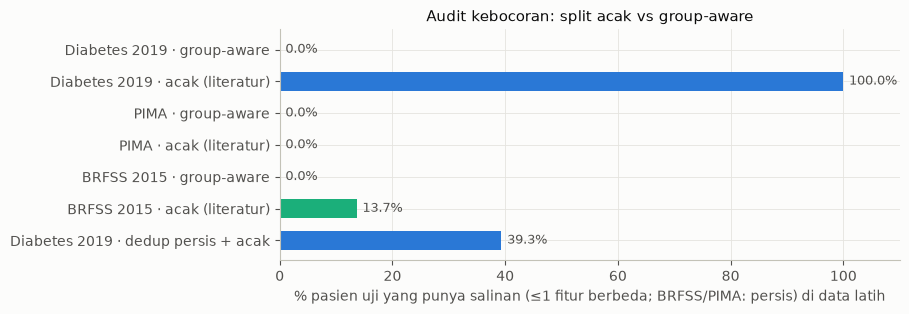

In [6]:
def split_indices(y, groups, protocol='group', test_size=TEST_SIZE, seed=SEED):
    idx = np.arange(len(y)); y = np.asarray(y)
    if protocol == 'group':
        sgkf = StratifiedGroupKFold(n_splits=int(round(1 / test_size)), shuffle=True, random_state=seed)
        tr, te = next(sgkf.split(idx, y, groups))
    else:
        tr, te = train_test_split(idx, test_size=test_size, stratify=y, random_state=seed)
    return np.sort(tr), np.sort(te)

def make_folds(y, groups, n_splits, protocol='group', seed=SEED):
    y = np.asarray(y); idx = np.arange(len(y))
    cv = (StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed) if protocol == 'group'
          else StratifiedKFold(n_splits, shuffle=True, random_state=seed))
    return [(tr, va) for tr, va in cv.split(idx, y, groups)]

def leakage_audit(X, tr, te, near=False):
    Xf = X.fillna(-999)
    h = pd.util.hash_pandas_object(Xf, index=False).to_numpy()
    out = {'% uji dgn salinan persis di latih': np.isin(h[te], h[tr]).mean() * 100}
    if near:
        A_tr, A_te = Xf.iloc[tr].to_numpy(), Xf.iloc[te].to_numpy()
        dmin = np.array([(A_tr != a).sum(axis=1).min() for a in A_te])
        out['% uji dgn salinan ≤1 fitur di latih'] = (dmin <= 1).mean() * 100
    return out

SPLITS = {}
audit_rows = []
for k, s in SPECS.items():
    for proto in ('group', 'random'):
        tr, te = split_indices(s.y, s.groups, proto)
        SPLITS[(k, proto)] = (tr, te)
        a = leakage_audit(s.X, tr, te, near=(k == 'diabetes2019'))
        audit_rows.append({'Dataset': s.title, 'Protokol': 'group-aware' if proto == 'group' else 'acak (literatur)',
                           'n latih': len(tr), 'n uji': len(te), 'Prevalensi uji': s.y.iloc[te].mean(), **a})
# Diabetes 2019: deduplikasi persis saja (tanpa grup) → apakah cukup?
_dd = pd.concat([X19, y19], axis=1).drop_duplicates().index.to_numpy()
_tr, _te = train_test_split(_dd, test_size=TEST_SIZE, stratify=y19.iloc[_dd], random_state=SEED)
audit_rows.append({'Dataset': 'Diabetes 2019', 'Protokol': 'dedup persis + acak', 'n latih': len(_tr), 'n uji': len(_te),
                   'Prevalensi uji': y19.iloc[_te].mean(), **leakage_audit(X19, _tr, _te, near=True)})
LEAKAGE_AUDIT = pd.DataFrame(audit_rows)
display(LEAKAGE_AUDIT)

fig, ax = plt.subplots(figsize=(8, 3))
lab = LEAKAGE_AUDIT['Dataset'] + ' · ' + LEAKAGE_AUDIT['Protokol']
col = '% uji dgn salinan ≤1 fitur di latih'
val = LEAKAGE_AUDIT[col].fillna(LEAKAGE_AUDIT['% uji dgn salinan persis di latih'])
ax.barh(lab, val, color=[DS_COLOR[[kk for kk, t in TITLE.items() if t == d][0]] for d in LEAKAGE_AUDIT['Dataset']], height=0.6)
for i, v in enumerate(val):
    ax.text(v + 1, i, f'{v:.1f}%', va='center', fontsize=9, color=TEXT2)
ax.invert_yaxis(); ax.set_xlim(0, 110)
ax.set(xlabel='% pasien uji yang punya salinan (≤1 fitur berbeda; BRFSS/PIMA: persis) di data latih',
       title='Audit kebocoran: split acak vs group-aware')
savefig(fig, 'fig02_leakage_audit')

## 5. Komponen Pipeline

* `DataFrameImputer` — imputasi median yang di-*fit* hanya pada *fold* latih.
* `TypeAwareResampler` — *oversampling* sadar tipe dan batas kelas: jarak k-NN dihitung pada ruang terstandardisasi (scaler di-*fit* pada *fold* latih), **SMOTE-NC** untuk data dominan nominal/biner (Diabetes 2019) atau **Borderline-SMOTE** untuk fitur kontinu/ordinal (PIMA, BRFSS); sampel sintetis dikembalikan ke satuan klinis asli dan kolom diskret dibulatkan sehingga tetap valid (mis. 0/1). Langkah ini hanya aktif saat `fit` (imblearn melewati *sampler* saat prediksi).
* `CostSensitiveXGB` — XGBoost dengan `scale_pos_weight = m · N⁻/N⁺` yang dihitung **setelah** *resampling* pada *fold* latih; *m* dioptimasi Optuna.
* `SHAPSelector` — seleksi fitur di dalam pipeline: melatih XGBoost internal pada *fold* latih, menghitung mean|SHAP| (TreeExplainer), dan mempertahankan fitur teratas hingga kumulatif ≥ 90%.
* `ProbabilityCalibrator` — Platt scaling (sigmoid pada logit) atau regresi isotonik, di-*fit* pada skor OOF.

In [7]:
class DataFrameImputer(BaseEstimator, TransformerMixin):
    """Imputasi median per kolom, di-fit hanya pada data latih (fold), mempertahankan nama kolom."""
    def __init__(self, strategy='median'):
        self.strategy = strategy
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.columns_ = list(X.columns)
        self.statistics_ = (X.median() if self.strategy == 'median' else X.mode().iloc[0]).fillna(0.0)
        return self
    def transform(self, X):
        X = pd.DataFrame(X)[self.columns_]
        return X.fillna(self.statistics_).astype(float)


class TypeAwareResampler(BaseEstimator):
    """Oversampling leakage-free (dipanggil imblearn hanya saat fit pada fold latih)."""
    def __init__(self, method='borderline', sampling_strategy=1.0, categorical=(), discrete=(),
                 k_neighbors=5, m_neighbors=10, random_state=SEED, n_jobs=N_JOBS):
        self.method = method; self.sampling_strategy = sampling_strategy; self.categorical = categorical
        self.discrete = discrete; self.k_neighbors = k_neighbors; self.m_neighbors = m_neighbors
        self.random_state = random_state; self.n_jobs = n_jobs

    def fit_resample(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True); y = np.asarray(y).astype(int)
        cols = list(X.columns)
        n_pos, n_neg = int(y.sum()), int(len(y) - y.sum())
        ratio = min(n_pos, n_neg) / max(n_pos, n_neg)
        r = self.sampling_strategy
        if r is None or r <= ratio + 1e-9:
            self.n_synthetic_ = 0
            return X, y
        scaler = StandardScaler().fit(X)                      # di-fit pada fold latih saja
        Xs = scaler.transform(X)
        k = int(min(self.k_neighbors, min(n_pos, n_neg) - 1))
        cat_idx = [cols.index(c) for c in self.categorical if c in cols]
        if self.method == 'smotenc' and 0 < len(cat_idx) < len(cols):
            sampler = SMOTENC(categorical_features=cat_idx, sampling_strategy=r, k_neighbors=k, random_state=self.random_state)
        elif self.method == 'borderline':
            sampler = BorderlineSMOTE(sampling_strategy=r, kind='borderline-1', random_state=self.random_state,
                                      k_neighbors=NearestNeighbors(n_neighbors=k + 1, n_jobs=self.n_jobs),
                                      m_neighbors=NearestNeighbors(n_neighbors=self.m_neighbors + 1, n_jobs=self.n_jobs))
        else:
            sampler = SMOTE(sampling_strategy=r, k_neighbors=k, random_state=self.random_state)
        Xr, yr = sampler.fit_resample(Xs, y)
        Xr = pd.DataFrame(scaler.inverse_transform(Xr), columns=cols)
        disc = [c for c in self.discrete if c in cols]
        if disc:
            Xr[disc] = Xr[disc].round()
        Xr = Xr.clip(lower=X.min(), upper=X.max(), axis=1)   # tetap dalam rentang nilai yang teramati
        self.n_synthetic_ = len(Xr) - len(X)
        return Xr, yr


class CostSensitiveXGB(BaseEstimator, ClassifierMixin):
    """XGBoost; spw_mult=None → bobot kelas default (1). Jika diisi: scale_pos_weight = spw_mult × N⁻/N⁺ (setelah resampling)."""
    def __init__(self, xgb_params=None, spw_mult=None, random_state=SEED, n_jobs=N_JOBS):
        self.xgb_params = xgb_params; self.spw_mult = spw_mult; self.random_state = random_state; self.n_jobs = n_jobs

    def fit(self, X, y):
        y = np.asarray(y).astype(int)
        pos = max(int(y.sum()), 1); neg = int(len(y) - y.sum())
        self.scale_pos_weight_ = 1.0 if self.spw_mult is None else float(self.spw_mult) * neg / pos
        self.model_ = xgb.XGBClassifier(**(self.xgb_params or {}), scale_pos_weight=self.scale_pos_weight_,
                                        tree_method='hist', eval_metric='logloss', random_state=self.random_state,
                                        n_jobs=self.n_jobs)
        self.model_.fit(X, y)
        self.classes_ = self.model_.classes_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    def predict(self, X):
        return self.model_.predict(X)


class SHAPSelector(BaseEstimator, TransformerMixin):
    """Seleksi fitur berbasis SHAP di dalam pipeline (di-fit hanya pada fold latih)."""
    def __init__(self, xgb_params=None, spw_mult=None, cum_threshold=SHAP_CUM, min_features=3,
                 max_rows=None, shap_rows=5000, random_state=SEED, n_jobs=N_JOBS):
        self.xgb_params = xgb_params; self.spw_mult = spw_mult; self.cum_threshold = cum_threshold
        self.min_features = min_features; self.max_rows = max_rows; self.shap_rows = shap_rows
        self.random_state = random_state; self.n_jobs = n_jobs

    def fit(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True); y = np.asarray(y).astype(int)
        idx = np.arange(len(y))
        if self.max_rows and len(y) > self.max_rows:
            idx, _ = train_test_split(idx, train_size=self.max_rows, stratify=y, random_state=self.random_state)
        model = CostSensitiveXGB(self.xgb_params, self.spw_mult, self.random_state, self.n_jobs).fit(X.iloc[idx], y[idx]).model_
        sidx = idx if len(idx) <= self.shap_rows else np.random.RandomState(self.random_state).choice(idx, self.shap_rows, replace=False)
        sv = shap.TreeExplainer(model).shap_values(X.iloc[sidx])
        imp = np.abs(np.asarray(sv)).mean(axis=0)
        order = np.argsort(-imp)
        cum = np.cumsum(imp[order]) / max(imp.sum(), 1e-12)
        k = int(min(len(order), max(self.min_features, np.searchsorted(cum, self.cum_threshold) + 1)))
        self.importances_ = pd.Series(imp, index=X.columns).sort_values(ascending=False)
        self.selected_ = [c for c in X.columns if c in set(X.columns[order[:k]])]
        self.k_ = k
        return self

    def transform(self, X):
        return pd.DataFrame(X)[self.selected_]

    def get_feature_names_out(self, input_features=None):
        return np.array(self.selected_)


def _logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, float), eps, 1 - eps)
    return np.log(p / (1 - p))


class ProbabilityCalibrator(BaseEstimator):
    """Kalibrasi pasca-hoc pada skor OOF: 'sigmoid' (Platt scaling pada logit) atau 'isotonic'."""
    def __init__(self, method='sigmoid'):
        self.method = method

    def fit(self, p, y):
        if self.method == 'sigmoid':
            lr = LogisticRegression(C=1e6, max_iter=1000).fit(_logit(p).reshape(-1, 1), np.asarray(y).astype(int))
            self.a_, self.b_ = float(lr.coef_[0, 0]), float(lr.intercept_[0])
        else:
            self.iso_ = IsotonicRegression(out_of_bounds='clip', y_min=0.0, y_max=1.0).fit(np.asarray(p, float), np.asarray(y))
        return self

    def transform(self, p):
        if self.method == 'sigmoid':
            return 1.0 / (1.0 + np.exp(-(self.a_ * _logit(p) + self.b_)))
        return self.iso_.predict(np.asarray(p, float))

    def to_dict(self):
        if self.method == 'sigmoid':
            return {'method': 'sigmoid', 'a': self.a_, 'b': self.b_}
        return {'method': 'isotonic', 'x': self.iso_.X_thresholds_.tolist(), 'y': self.iso_.y_thresholds_.tolist()}


def build_pipeline(spec, xgb_params=None, spw_mult=None, sampling=None, select=False):
    steps = [('impute', DataFrameImputer())]
    if select:
        steps.append(('select', SHAPSelector(xgb_params=xgb_params, spw_mult=spw_mult, **SELECTOR_CFG[spec.key])))
    if sampling is not None:
        steps.append(('resample', TypeAwareResampler(method=spec.sampler, sampling_strategy=sampling,
                                                     categorical=tuple(spec.categorical), discrete=tuple(spec.discrete))))
    steps.append(('clf', CostSensitiveXGB(xgb_params=xgb_params, spw_mult=spw_mult)))
    return Pipeline(steps)


def transform_features(pipe, X):
    """Terapkan langkah transformasi (imputasi, seleksi) tanpa sampler → input model untuk SHAP/inferensi."""
    Xt = X
    for _, step in pipe.steps[:-1]:
        if hasattr(step, 'transform'):
            Xt = step.transform(Xt)
    return Xt

# Uji unit cepat: sampler tidak mengubah data uji, kolom diskret tetap valid, rasio kelas sesuai target
_s = SPECS['diabetes2019']; _tr, _te = SPLITS[('diabetes2019', 'group')]
_rs = TypeAwareResampler('smotenc', 1.0, tuple(_s.categorical), tuple(_s.discrete))
_Xi = DataFrameImputer().fit(_s.X.iloc[_tr]).transform(_s.X.iloc[_tr])
_Xr, _yr = _rs.fit_resample(_Xi, _s.y.iloc[_tr])
assert set(np.unique(_Xr[_s.categorical].to_numpy())) <= {0.0, 1.0} and abs(_yr.mean() - 0.5) < 0.01
print(f'Uji resampler OK: {len(_Xi)} → {len(_Xr)} baris latih (+{_rs.n_synthetic_} sintetis), proporsi positif {_yr.mean():.3f}; data uji tidak disentuh.')

Uji resampler OK: 764 → 1104 baris latih (+340 sintetis), proporsi positif 0.500; data uji tidak disentuh.


## 6. Mesin Evaluasi

* **Metrik klinis**: Accuracy, Precision (PPV), Recall/Sensitivity, Specificity, F1, ROC-AUC, AUPRC, Brier score, FNR, ditambah Balanced Accuracy, G-mean, NPV, ECE, F1 makro/berbobot (untuk komparasi dengan paper yang memakai rata-rata makro/berbobot).
* **Ambang keputusan** (S2–S4) dipilih dengan memaksimalkan F2 pada prediksi **OOF data latih**; S0–S1 memakai ambang bawaan 0,5.
* **Cross-fitting**: metrik CV per *fold* memakai ambang (dan kalibrator) yang di-*fit* hanya pada *fold* lain, sehingga estimasi CV tidak bias.
* **Kalibrasi S4**: kalibrator di-*fit* pada skor OOF 10-fold dari S3, lalu diterapkan ke prediksi uji model final — setara `CalibratedClassifierCV(cv=10, ensemble=False)` tanpa melatih ulang model.

In [8]:
MAIN = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'ROC_AUC', 'AUPRC', 'Brier', 'FNR']

def ece_score(y, p, n_bins=10):
    y = np.asarray(y); p = np.asarray(p, float)
    b = np.clip((p * n_bins).astype(int), 0, n_bins - 1)
    return float(sum((b == i).mean() * abs(p[b == i].mean() - y[b == i].mean()) for i in range(n_bins) if (b == i).any()))

def clinical_metrics(y, p, thr):
    y = np.asarray(y).astype(int); p = np.asarray(p, float); yhat = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if tp + fn else np.nan
    spec = tn / (tn + fp) if tn + fp else np.nan
    prec = tp / (tp + fp) if tp + fp else 0.0
    f1 = 2 * prec * sens / (prec + sens) if prec + sens else 0.0
    f2 = 5 * prec * sens / (4 * prec + sens) if 4 * prec + sens else 0.0
    return {'Accuracy': (tp + tn) / len(y), 'Precision': prec, 'Recall': sens, 'Specificity': spec, 'F1': f1, 'F2': f2,
            'ROC_AUC': roc_auc_score(y, p), 'AUPRC': average_precision_score(y, p), 'Brier': brier_score_loss(y, p),
            'FNR': 1 - sens, 'BalancedAcc': (sens + spec) / 2, 'GMean': float(np.sqrt(sens * spec)),
            'NPV': tn / (tn + fn) if tn + fn else np.nan, 'ECE': ece_score(y, p),
            'MacroF1': f1_score(y, yhat, average='macro', zero_division=0),
            'WeightedF1': f1_score(y, yhat, average='weighted', zero_division=0),
            'Threshold': thr, 'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn)}

def select_threshold(y, p, beta=F_BETA):
    """Ambang yang memaksimalkan F-beta pada skor OOF (data latih)."""
    y = np.asarray(y).astype(int); p = np.asarray(p, float)
    grid = np.unique(np.quantile(p, np.linspace(0.002, 0.998, 499)))
    ps, ns = np.sort(p[y == 1]), np.sort(p[y == 0])
    tp = len(ps) - np.searchsorted(ps, grid, side='left')
    fp = len(ns) - np.searchsorted(ns, grid, side='left')
    prec = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1), 0.0)
    rec = tp / max(len(ps), 1)
    b2 = beta ** 2
    fb = np.where(b2 * prec + rec > 0, (1 + b2) * prec * rec / np.maximum(b2 * prec + rec, 1e-12), 0.0)
    return float(grid[np.argmax(fb)])

def tier_cutoffs(y, p, sens_target=TIER_SENS, spec_target=TIER_SPEC):
    """t_low: ambang terbesar dgn sensitivitas ≥ target; t_high: ambang terkecil dgn spesifisitas ≥ target."""
    y = np.asarray(y).astype(int); p = np.asarray(p, float)
    grid = np.unique(np.quantile(p, np.linspace(0, 1, 2001)))
    ps, ns = np.sort(p[y == 1]), np.sort(p[y == 0])
    sens = 1 - np.searchsorted(ps, grid, side='left') / len(ps)
    spec = np.searchsorted(ns, grid, side='left') / len(ns)
    t_low = float(grid[sens >= sens_target].max())
    t_high = float(grid[spec >= spec_target].min()) if (spec >= spec_target).any() else float(grid.max())
    return t_low, max(t_high, t_low)

@dataclass
class ScenarioResult:
    name: str
    cv: pd.DataFrame          # metrik per fold (cross-fitted)
    test: dict                # metrik test set
    oof: np.ndarray           # skor OOF mentah (data latih)
    p_test: np.ndarray        # probabilitas akhir pada test set
    thr: float
    extras: dict = field(default_factory=dict)

def oof_predict(factory, X, y, folds):
    oof = np.zeros(len(y))
    for tr, va in folds:
        m = factory().fit(X.iloc[tr], y.iloc[tr])
        oof[va] = m.predict_proba(X.iloc[va])[:, 1]
    return oof

def cv_metrics(oof, y, folds, tune_threshold, calibrate=None):
    y = np.asarray(y); rows = []
    for tr, va in folds:
        p_tr, p_va = oof[tr], oof[va]
        if calibrate:
            cal = ProbabilityCalibrator(calibrate).fit(p_tr, y[tr])
            p_tr, p_va = cal.transform(p_tr), cal.transform(p_va)
        thr = select_threshold(y[tr], p_tr) if tune_threshold else 0.5
        rows.append(clinical_metrics(y[va], p_va, thr))
    return pd.DataFrame(rows)

def run_scenario(name, spec, tr, te, folds, factory, tune_threshold=True):
    t0 = time.time()
    X_tr, y_tr, X_te, y_te = spec.X.iloc[tr], spec.y.iloc[tr], spec.X.iloc[te], spec.y.iloc[te]
    oof = oof_predict(factory, X_tr, y_tr, folds)
    final = factory().fit(X_tr, y_tr)
    p_te = final.predict_proba(X_te)[:, 1]
    thr = select_threshold(y_tr, oof) if tune_threshold else 0.5
    res = ScenarioResult(name, cv_metrics(oof, y_tr, folds, tune_threshold), clinical_metrics(y_te, p_te, thr), oof, p_te, thr,
                         {'model': final, 'p_test_raw': p_te, 'oof_used': oof, 'seconds': time.time() - t0})
    print(f'   {name:<7} selesai dalam {time.time() - t0:6.1f} dtk | test: Recall={res.test["Recall"]:.3f} '
          f'Spec={res.test["Specificity"]:.3f} F1={res.test["F1"]:.3f} AUPRC={res.test["AUPRC"]:.3f} Brier={res.test["Brier"]:.4f}')
    return res

def run_calibrated(name, base, spec, tr, te, folds, method):
    y_tr, y_te = spec.y.iloc[tr].to_numpy(), spec.y.iloc[te]
    cal = ProbabilityCalibrator(method).fit(base.oof, y_tr)
    oof_cal, p_te = cal.transform(base.oof), cal.transform(base.extras['p_test_raw'])
    thr = select_threshold(y_tr, oof_cal)
    res = ScenarioResult(name, cv_metrics(base.oof, y_tr, folds, True, method), clinical_metrics(y_te, p_te, thr), base.oof, p_te,
                         thr, {**base.extras, 'calibrator': cal, 'oof_used': oof_cal, 'method': method})
    print(f'   {name:<7} kalibrasi {method} | test: Recall={res.test["Recall"]:.3f} Spec={res.test["Specificity"]:.3f} '
          f'F1={res.test["F1"]:.3f} AUPRC={res.test["AUPRC"]:.3f} Brier={res.test["Brier"]:.4f}')
    return res

### 6.1 Tuning hiperparameter dengan Optuna (TPE, *Bayesian optimization*)

Fungsi objektif = rata-rata **AUPRC** pada *inner* CV (stratified group k-fold) **di dalam data latih**. Ruang pencarian mencakup hiperparameter XGBoost, pengali biaya *m* untuk `scale_pos_weight`, dan rasio *resampling* *r* (minoritas:mayoritas setelah *oversampling*; S2 memaksa *r* > rasio alami agar *resampling* benar-benar aktif). Untuk BRFSS, *inner* CV dijalankan pada subsampel stratified 40.000 baris data latih demi efisiensi.

In [9]:
def tune(spec, tr, use_resampling, n_trials, inner_folds, max_rows):
    X_tr, y_tr, g_tr = spec.X.iloc[tr], spec.y.iloc[tr], spec.groups[tr]
    if max_rows and len(tr) > max_rows:
        sub, _ = train_test_split(np.arange(len(tr)), train_size=max_rows, stratify=y_tr, random_state=SEED)
        X_tr, y_tr, g_tr = X_tr.iloc[sub], y_tr.iloc[sub], g_tr[sub]
    folds = make_folds(y_tr, g_tr, inner_folds, 'group')
    natural = y_tr.mean() / (1 - y_tr.mean())
    r_lo = float(min(0.95, max(0.3, natural + 0.05)))

    def objective(trial):
        params = dict(
            n_estimators=trial.suggest_int('n_estimators', 100, 600, step=50),
            max_depth=trial.suggest_int('max_depth', 2, 8),
            learning_rate=trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            subsample=trial.suggest_float('subsample', 0.6, 1.0),
            colsample_bytree=trial.suggest_float('colsample_bytree', 0.5, 1.0),
            min_child_weight=trial.suggest_float('min_child_weight', 1.0, 20.0, log=True),
            gamma=trial.suggest_float('gamma', 0.0, 5.0),
            reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
            reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True))
        spw = trial.suggest_float('spw_mult', 0.5, 3.0, log=True)
        r = trial.suggest_float('sampling_strategy', r_lo, 1.0) if use_resampling else None
        scores = []
        for step, (a, b) in enumerate(folds):
            pipe = build_pipeline(spec, params, spw, r).fit(X_tr.iloc[a], y_tr.iloc[a])
            scores.append(average_precision_score(y_tr.iloc[b], pipe.predict_proba(X_tr.iloc[b])[:, 1]))
            trial.report(float(np.mean(scores)), step)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return float(np.mean(scores))

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=1))
    t0 = time.time()
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
    bp = dict(study.best_params)
    spw = bp.pop('spw_mult'); r = bp.pop('sampling_strategy', None)
    print(f'   Optuna ({"dengan" if use_resampling else "tanpa"} resampling): {n_trials} trial, {time.time() - t0:.0f} dtk, '
          f'AUPRC inner-CV terbaik={study.best_value:.4f}, r={r if r is None else round(r, 3)}, m={spw:.3f}')
    return {'xgb_params': bp, 'spw_mult': spw, 'sampling': r, 'inner_auprc': study.best_value,
            'n_trials_complete': sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)}

## 7. Studi Ablasi S0–S4

| Skenario | Komponen | Ambang |
|---|---|---|
| **S0** Baseline | XGBoost bawaan, tanpa *balancing*, tanpa *tuning* | 0,5 |
| **S1** + *Leakage-free resampling* | S0 + SMOTE-NC / Borderline-SMOTE (r = 1,0) hanya pada *fold* latih | 0,5 |
| **S2** + *Cost-sensitive* & *tuning* | *Resampling* (r dioptimasi) + `scale_pos_weight` + Optuna + ambang F2 | OOF-F2 |
| **S2′** Kontrol | Seperti S2 tetapi **tanpa** *resampling* (memisahkan kontribusi *resampling*) | OOF-F2 |
| **S3** + Seleksi fitur SHAP | S2 + `SHAPSelector` (kumulatif 90% mean\|SHAP\|) di dalam pipeline | OOF-F2 |
| **S4** Model lengkap + kalibrasi | S3 + kalibrasi Platt/isotonik (dipilih via Brier OOF *cross-fitted*) | OOF-F2 terkalibrasi |

Semua skenario memakai *split* dan *fold* yang sama, sehingga perbandingan antar-skenario bersifat berpasangan (*paired*).

In [10]:
def run_dataset(spec, protocol='group'):
    print(f'\n=== {spec.title} | protokol {protocol} ===')
    tr, te = SPLITS[(spec.key, protocol)]
    folds = make_folds(spec.y.iloc[tr], spec.groups[tr], N_FOLDS, protocol)
    R = {}
    R['S0'] = run_scenario('S0', spec, tr, te, folds, lambda: build_pipeline(spec), tune_threshold=False)
    R['S1'] = run_scenario('S1', spec, tr, te, folds, lambda: build_pipeline(spec, sampling=1.0), tune_threshold=False)
    best = tune(spec, tr, True, **OPTUNA_CFG[spec.key])
    best_nr = tune(spec, tr, False, **OPTUNA_CFG[spec.key])
    R['S2'] = run_scenario('S2', spec, tr, te, folds,
                           lambda: build_pipeline(spec, best['xgb_params'], best['spw_mult'], best['sampling']))
    R['S2′'] = run_scenario('S2′', spec, tr, te, folds,
                            lambda: build_pipeline(spec, best_nr['xgb_params'], best_nr['spw_mult'], None))
    R['S3'] = run_scenario('S3', spec, tr, te, folds,
                           lambda: build_pipeline(spec, best['xgb_params'], best['spw_mult'], best['sampling'], select=True))
    y_tr = spec.y.iloc[tr].to_numpy()
    # isotonik rawan overfitting pada n < 1000 (panduan scikit-learn) → hanya Platt untuk data latih kecil
    candidates = ('sigmoid',) if len(tr) < 1000 else ('sigmoid', 'isotonic')
    briers = {m: cv_metrics(R['S3'].oof, y_tr, folds, True, m)['Brier'].mean() for m in candidates}
    method = min(briers, key=briers.get)
    R['S4'] = run_calibrated('S4', R['S3'], spec, tr, te, folds, method)
    return {'tr': tr, 'te': te, 'folds': folds, 'R': R, 'tuning': {'S2': best, 'S2′': best_nr},
            'cal_briers_cv': briers, 'cal_method': method}

RESULTS = {}
for k in SPECS:
    t0 = time.time()
    RESULTS[k] = run_dataset(SPECS[k])
    print(f'   Total {SPECS[k].title}: {(time.time() - t0) / 60:.1f} menit')


=== Diabetes 2019 | protokol group ===
   S0      selesai dalam    2.8 dtk | test: Recall=0.556 Spec=0.895 F1=0.612 AUPRC=0.719 Brier=0.1725
   S1      selesai dalam    2.0 dtk | test: Recall=0.704 Spec=0.865 F1=0.691 AUPRC=0.686 Brier=0.1576
   Optuna (dengan resampling): 60 trial, 42 dtk, AUPRC inner-CV terbaik=0.7871, r=0.535, m=2.373
   Optuna (tanpa resampling): 60 trial, 14 dtk, AUPRC inner-CV terbaik=0.7747, r=None, m=1.062
   S2      selesai dalam    1.8 dtk | test: Recall=0.685 Spec=0.857 F1=0.673 AUPRC=0.689 Brier=0.1458
   S2′     selesai dalam    0.7 dtk | test: Recall=0.926 Spec=0.774 F1=0.746 AUPRC=0.776 Brier=0.1255
   S3      selesai dalam    3.0 dtk | test: Recall=0.796 Spec=0.842 F1=0.729 AUPRC=0.702 Brier=0.1393
   S4      kalibrasi sigmoid | test: Recall=0.796 Spec=0.842 F1=0.729 AUPRC=0.702 Brier=0.1433
   Total Diabetes 2019: 1.1 menit

=== PIMA | protokol group ===
   S0      selesai dalam    0.8 dtk | test: Recall=0.593 Spec=0.820 F1=0.615 AUPRC=0.674 Brier=0.2

In [11]:
SCEN_LABEL = {'S0': 'S0 Baseline', 'S1': 'S1 +Resampling', 'S2': 'S2 +Cost-sens.+Tuning', 'S2′': 'S2′ Kontrol tanpa RS',
              'S3': 'S3 +Seleksi SHAP', 'S4': 'S4 +Kalibrasi (lengkap)'}

def n_features(res, k):
    m = res.extras['model']
    return len(m.named_steps['select'].selected_) if 'select' in m.named_steps else SPECS[k].X.shape[1]

def ablation_tables(results):
    test_rows, cv_rows = [], []
    for k, out in results.items():
        for s, r in out['R'].items():
            base = {'Dataset': TITLE[k], 'Skenario': SCEN_LABEL[s], 'n fitur': n_features(r, k), 'Ambang': r.thr}
            test_rows.append({**base, **{m: r.test[m] for m in MAIN}})
            mu, sd = r.cv[MAIN].mean(), r.cv[MAIN].std()
            cv_rows.append({**base, **{m: f'{mu[m]:.3f} ± {sd[m]:.3f}' for m in MAIN}})
    return pd.DataFrame(test_rows), pd.DataFrame(cv_rows)

ABL_TEST, ABL_CV = ablation_tables(RESULTS)
print('Hasil ablasi pada TEST SET (20%, tidak pernah disentuh selama pelatihan/tuning):')
display(ABL_TEST)
print(f'Hasil ablasi {N_FOLDS}-fold CV (mean ± std, ambang & kalibrator cross-fitted):')
display(ABL_CV)
ABL_TEST.to_csv(OUT / 'ablation_test.csv', index=False); ABL_CV.to_csv(OUT / 'ablation_cv.csv', index=False)
for k, out in RESULTS.items():
    t = out['tuning']['S2']
    print(f"{TITLE[k]:>13} · S2 terbaik: r={t['sampling']:.3f}, m={t['spw_mult']:.3f}, params={ {a: (round(b, 4) if isinstance(b, float) else b) for a, b in t['xgb_params'].items()} }")
    print(f"{'':>13}   kalibrasi S4: {out['cal_method']} (Brier CV per kandidat: "
          f"{ {m: round(float(v), 4) for m, v in out['cal_briers_cv'].items()} })")

Hasil ablasi pada TEST SET (20%, tidak pernah disentuh selama pelatihan/tuning):


,Dataset,Skenario,n fitur,Ambang,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,AUPRC,Brier,FNR
0,Diabetes 2019,S0 Baseline,17,0.5000,0.7968,0.6818,0.5556,0.8947,0.6122,0.8473,0.7191,0.1725,0.4444
1,Diabetes 2019,S1 +Resampling,17,0.5000,0.8182,0.6786,0.7037,0.8647,0.6909,0.8488,0.6858,0.1576,0.2963
2,Diabetes 2019,S2 +Cost-sens.+Tuning,17,0.4590,0.8075,0.6607,0.6852,0.8571,0.6727,0.8516,0.6893,0.1458,0.3148
3,Diabetes 2019,S2′ Kontrol tanpa RS,17,0.0571,0.8182,0.6250,0.9259,0.7744,0.7463,0.8761,0.7755,0.1255,0.0741
4,Diabetes 2019,S3 +Seleksi SHAP,10,0.2746,0.8289,0.6719,0.7963,0.8421,0.7288,0.8661,0.7023,0.1393,0.2037
5,Diabetes 2019,S4 +Kalibrasi (lengkap),10,0.1627,0.8289,0.6719,0.7963,0.8421,0.7288,0.8661,0.7023,0.1433,0.2037
6,PIMA,S0 Baseline,8,0.5000,0.7403,0.6400,0.5926,0.8200,0.6154,0.7746,0.6744,0.2151,0.4074
7,PIMA,S1 +Resampling,8,0.5000,0.7403,0.6207,0.6667,0.7800,0.6429,0.7756,0.6759,0.2148,0.3333
8,PIMA,S2 +Cost-sens.+Tuning,8,0.1878,0.6234,0.4808,0.9259,0.4600,0.6329,0.8431,0.7755,0.1521,0.0741
9,PIMA,S2′ Kontrol tanpa RS,8,0.2358,0.6494,0.5000,0.9630,0.4800,0.6582,0.8459,0.7664,0.1545,0.0370


Hasil ablasi 10-fold CV (mean ± std, ambang & kalibrator cross-fitted):


,Dataset,Skenario,n fitur,Ambang,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,AUPRC,Brier,FNR
0,Diabetes 2019,S0 Baseline,17,0.5000,0.862 ± 0.103,0.750 ± 0.205,0.787 ± 0.185,0.892 ± 0.090,0.760 ± 0.177,0.894 ± 0.084,0.791 ± 0.144,0.113 ± 0.067,0.213 ± 0.185
1,Diabetes 2019,S1 +Resampling,17,0.5000,0.837 ± 0.070,0.705 ± 0.150,0.772 ± 0.145,0.864 ± 0.085,0.726 ± 0.109,0.895 ± 0.078,0.783 ± 0.154,0.136 ± 0.072,0.228 ± 0.145
2,Diabetes 2019,S2 +Cost-sens.+Tuning,17,0.4590,0.782 ± 0.070,0.586 ± 0.118,0.865 ± 0.160,0.751 ± 0.099,0.688 ± 0.096,0.915 ± 0.076,0.826 ± 0.131,0.121 ± 0.065,0.135 ± 0.160
3,Diabetes 2019,S2′ Kontrol tanpa RS,17,0.0571,0.753 ± 0.107,0.550 ± 0.142,0.897 ± 0.129,0.699 ± 0.123,0.675 ± 0.126,0.900 ± 0.080,0.799 ± 0.145,0.121 ± 0.059,0.103 ± 0.129
4,Diabetes 2019,S3 +Seleksi SHAP,10,0.2746,0.775 ± 0.085,0.572 ± 0.118,0.879 ± 0.157,0.737 ± 0.103,0.686 ± 0.112,0.901 ± 0.077,0.794 ± 0.127,0.127 ± 0.057,0.121 ± 0.157
5,Diabetes 2019,S4 +Kalibrasi (lengkap),10,0.1627,0.775 ± 0.085,0.572 ± 0.118,0.879 ± 0.157,0.737 ± 0.103,0.686 ± 0.112,0.901 ± 0.077,0.794 ± 0.127,0.112 ± 0.045,0.121 ± 0.157
6,PIMA,S0 Baseline,8,0.5000,0.735 ± 0.030,0.627 ± 0.045,0.602 ± 0.111,0.805 ± 0.057,0.608 ± 0.066,0.800 ± 0.038,0.662 ± 0.060,0.201 ± 0.021,0.398 ± 0.111
7,PIMA,S1 +Resampling,8,0.5000,0.749 ± 0.039,0.631 ± 0.064,0.691 ± 0.125,0.780 ± 0.065,0.654 ± 0.071,0.813 ± 0.041,0.676 ± 0.066,0.199 ± 0.031,0.309 ± 0.125
8,PIMA,S2 +Cost-sens.+Tuning,8,0.1878,0.669 ± 0.074,0.526 ± 0.071,0.878 ± 0.101,0.557 ± 0.144,0.652 ± 0.048,0.830 ± 0.054,0.712 ± 0.081,0.160 ± 0.022,0.122 ± 0.101
9,PIMA,S2′ Kontrol tanpa RS,8,0.2358,0.648 ± 0.056,0.502 ± 0.042,0.915 ± 0.100,0.505 ± 0.112,0.645 ± 0.038,0.838 ± 0.049,0.726 ± 0.067,0.158 ± 0.018,0.085 ± 0.100


Diabetes 2019 · S2 terbaik: r=0.535, m=2.373, params={'n_estimators': 150, 'max_depth': 6, 'learning_rate': 0.0197, 'subsample': 0.9576, 'colsample_bytree': 0.8755, 'min_child_weight': 1.1993, 'gamma': 0.5037, 'reg_lambda': 0.0306, 'reg_alpha': 0.0357}
                kalibrasi S4: sigmoid (Brier CV per kandidat: {'sigmoid': 0.1117})
         PIMA · S2 terbaik: r=0.653, m=0.582, params={'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.1037, 'subsample': 0.7384, 'colsample_bytree': 0.7422, 'min_child_weight': 6.8087, 'gamma': 3.3156, 'reg_lambda': 0.0196, 'reg_alpha': 0.8153}
                kalibrasi S4: sigmoid (Brier CV per kandidat: {'sigmoid': 0.16})
   BRFSS 2015 · S2 terbaik: r=0.313, m=0.796, params={'n_estimators': 250, 'max_depth': 3, 'learning_rate': 0.0168, 'subsample': 0.6496, 'colsample_bytree': 0.8031, 'min_child_weight': 11.9256, 'gamma': 2.6358, 'reg_lambda': 0.0388, 'reg_alpha': 0.2065}
                kalibrasi S4: isotonic (Brier CV per kandidat: {'sigmoid': 0

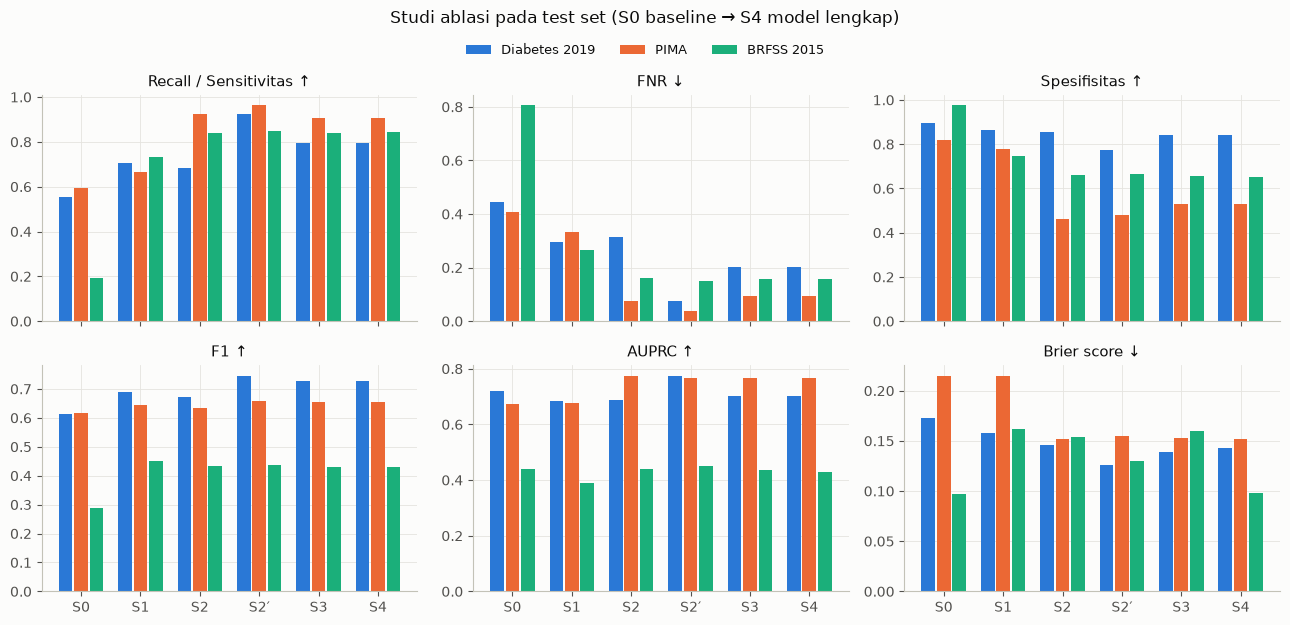

In [12]:
metrics_plot = [('Recall', 'Recall / Sensitivitas ↑'), ('FNR', 'FNR ↓'), ('Specificity', 'Spesifisitas ↑'),
                ('F1', 'F1 ↑'), ('AUPRC', 'AUPRC ↑'), ('Brier', 'Brier score ↓')]
scen = list(SCEN_LABEL)
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2), sharex=True)
w = 0.26
for ax, (m, ttl) in zip(axes.ravel(), metrics_plot):
    for i, k in enumerate(RESULTS):
        vals = [RESULTS[k]['R'][s].test[m] for s in scen]
        ax.bar(np.arange(len(scen)) + (i - 1) * w, vals, width=w - 0.03, color=DS_COLOR[k], label=TITLE[k])
    ax.set_title(ttl); ax.set_xticks(np.arange(len(scen))); ax.set_xticklabels(scen)
fig.tight_layout(rect=(0, 0, 1, 0.92))
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 0.965), fontsize=9)
fig.suptitle('Studi ablasi pada test set (S0 baseline → S4 model lengkap)', y=1.0)
savefig(fig, 'fig03_ablation')

### 7.1 Efek pemilihan ambang dan uji signifikansi berpasangan
* Tabel pertama memisahkan kontribusi **ambang F2** dari kontribusi *cost-sensitive learning*/tuning dengan mengevaluasi S2 pada ambang 0,5 dan pada ambang OOF-F2.
* Uji **Wilcoxon signed-rank** (dua sisi) pada metrik per-*fold* yang berpasangan (fold sama) membandingkan S2 dan S4 terhadap S0.
* **Bootstrap berpasangan** (1.000 replikasi; *group bootstrap* untuk Diabetes 2019) pada test set memberi interval kepercayaan 95% untuk selisih metrik.

In [13]:
rows = []
for k, out in RESULTS.items():
    r = out['R']['S2']; y_te = SPECS[k].y.iloc[out['te']]
    for lbl, t in [('ambang 0,5', 0.5), ('ambang OOF-F2', r.thr)]:
        m = clinical_metrics(y_te, r.p_test, t)
        rows.append({'Dataset': TITLE[k], 'S2 dievaluasi pada': lbl, 'Ambang': t, **{x: m[x] for x in ['Recall', 'Specificity', 'Precision', 'F1', 'FNR']}})
THR_EFFECT = pd.DataFrame(rows); display(THR_EFFECT)

def wilcoxon_p(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    if np.allclose(a - b, 0):
        return 1.0
    return float(stats.wilcoxon(a, b).pvalue)

rows = []
for k, out in RESULTS.items():
    R = out['R']
    for comp in ['S2', 'S4']:
        for m in ['FNR', 'Recall', 'Specificity', 'F1', 'AUPRC', 'Brier']:
            rows.append({'Dataset': TITLE[k], 'Perbandingan': f'{comp} vs S0', 'Metrik': m,
                         'Mean S0': R['S0'].cv[m].mean(), f'Mean pembanding': R[comp].cv[m].mean(),
                         'Δ (pembanding − S0)': R[comp].cv[m].mean() - R['S0'].cv[m].mean(),
                         'p Wilcoxon': wilcoxon_p(R[comp].cv[m], R['S0'].cv[m])})
WILCOX = pd.DataFrame(rows); display(WILCOX)

def fast_metrics(y, p, thr):
    yhat = p >= thr; pos = y == 1
    tp = (yhat & pos).sum(); fn = (~yhat & pos).sum(); tn = (~yhat & ~pos).sum(); fp = (yhat & ~pos).sum()
    rec = tp / max(tp + fn, 1); prec = tp / max(tp + fp, 1)
    return {'Recall': rec, 'FNR': 1 - rec, 'Specificity': tn / max(tn + fp, 1),
            'F1': 2 * prec * rec / max(prec + rec, 1e-12), 'AUPRC': average_precision_score(y, p),
            'ROC_AUC': roc_auc_score(y, p), 'Brier': float(np.mean((p - y) ** 2))}

def paired_bootstrap(y, pa, ta, pb, tb, groups=None, n_boot=N_BOOT, seed=SEED):
    """Selisih metrik (B − A) pada resampel bootstrap test set yang sama. Group bootstrap bila groups diberikan."""
    rng = np.random.RandomState(seed); y = np.asarray(y).astype(int); pa = np.asarray(pa); pb = np.asarray(pb)
    if groups is not None:
        ug = np.unique(groups); pos_by_g = pd.Series(np.arange(len(y))).groupby(groups).apply(np.array).to_dict()
    diffs = []
    for _ in range(n_boot):
        idx = (rng.randint(0, len(y), len(y)) if groups is None
               else np.concatenate([pos_by_g[g] for g in rng.choice(ug, len(ug), replace=True)]))
        yy = y[idx]
        if yy.min() == yy.max():
            continue
        a, b = fast_metrics(yy, pa[idx], ta), fast_metrics(yy, pb[idx], tb)
        diffs.append({m: b[m] - a[m] for m in a})
    D = pd.DataFrame(diffs)
    return pd.DataFrame({'Δ titik': {m: fast_metrics(y, pb, tb)[m] - fast_metrics(y, pa, ta)[m] for m in D},
                         'CI95 bawah': D.quantile(0.025), 'CI95 atas': D.quantile(0.975)})

BOOT = {}
for k, out in RESULTS.items():
    R = out['R']; te = out['te']; y_te = SPECS[k].y.iloc[te].to_numpy()
    grp = SPECS[k].groups[te] if k == 'diabetes2019' else None
    nb = N_BOOT if k != 'brfss' else min(N_BOOT, 300)
    BOOT[(k, 'S2 vs S0')] = paired_bootstrap(y_te, R['S0'].p_test, R['S0'].thr, R['S2'].p_test, R['S2'].thr, grp, nb)
    BOOT[(k, 'S4 vs S3')] = paired_bootstrap(y_te, R['S3'].p_test, R['S3'].thr, R['S4'].p_test, R['S4'].thr, grp, nb)
    BOOT[(k, 'S3 vs S2')] = paired_bootstrap(y_te, R['S2'].p_test, R['S2'].thr, R['S3'].p_test, R['S3'].thr, grp, nb)
    BOOT[(k, 'S2 vs S2′')] = paired_bootstrap(y_te, R['S2′'].p_test, R['S2′'].thr, R['S2'].p_test, R['S2'].thr, grp, nb)
BOOT_TABLE = pd.concat({f'{TITLE[k]} · {c}': v for (k, c), v in BOOT.items()})
display(BOOT_TABLE)
BOOT_TABLE.to_csv(OUT / 'bootstrap_paired_differences.csv')

,Dataset,S2 dievaluasi pada,Ambang,Recall,Specificity,Precision,F1,FNR
0,Diabetes 2019,"ambang 0,5",0.5000,0.6852,0.8571,0.6607,0.6727,0.3148
1,Diabetes 2019,ambang OOF-F2,0.4590,0.6852,0.8571,0.6607,0.6727,0.3148
2,PIMA,"ambang 0,5",0.5000,0.6296,0.8100,0.6415,0.6355,0.3704
3,PIMA,ambang OOF-F2,0.1878,0.9259,0.4600,0.4808,0.6329,0.0741
4,BRFSS 2015,"ambang 0,5",0.5000,0.7424,0.7585,0.3370,0.4636,0.2576
5,BRFSS 2015,ambang OOF-F2,0.3943,0.8401,0.6622,0.2915,0.4328,0.1599


,Dataset,Perbandingan,Metrik,Mean S0,Mean pembanding,Δ (pembanding − S0),p Wilcoxon
0,Diabetes 2019,S2 vs S0,FNR,0.2127,0.1351,-0.0776,0.1250
1,Diabetes 2019,S2 vs S0,Recall,0.7873,0.8649,0.0776,0.1250
2,Diabetes 2019,S2 vs S0,Specificity,0.8919,0.7514,-0.1405,0.0039
3,Diabetes 2019,S2 vs S0,F1,0.7603,0.6880,-0.0724,0.0977
4,Diabetes 2019,S2 vs S0,AUPRC,0.7912,0.8256,0.0344,0.1934
5,Diabetes 2019,S2 vs S0,Brier,0.1134,0.1215,0.0081,0.4922
6,Diabetes 2019,S4 vs S0,FNR,0.2127,0.1208,-0.0919,0.0156
7,Diabetes 2019,S4 vs S0,Recall,0.7873,0.8792,0.0919,0.0156
8,Diabetes 2019,S4 vs S0,Specificity,0.8919,0.7368,-0.1550,0.0020
9,Diabetes 2019,S4 vs S0,F1,0.7603,0.6857,-0.0746,0.0645


Δ titik  CI95 bawah  CI95 atas
Diabetes 2019 · S2 vs S0 Recall        0.1296     -0.0626     0.3572
                         FNR          -0.1296     -0.3572     0.0626
                         Specificity  -0.0376     -0.1261     0.0313
                         F1            0.0605     -0.0697     0.2318
                         AUPRC        -0.0298     -0.0976     0.0326
...                                       ...         ...        ...
BRFSS 2015 · S2 vs S2′   Specificity  -0.0011     -0.0033     0.0010
                         F1           -0.0040     -0.0065    -0.0016
                         AUPRC        -0.0116     -0.0157    -0.0079
                         ROC_AUC      -0.0052     -0.0062    -0.0039
                         Brier         0.0231      0.0225     0.0236

[84 rows x 3 columns]

## 8. Analisis Kalibrasi Probabilitas (H3)
Kurva reliabilitas pada test set: skor mentah S3 (setelah *resampling* + `scale_pos_weight`, sehingga cenderung *overestimate*) vs probabilitas terkalibrasi S4. Garis diagonal = kalibrasi sempurna.

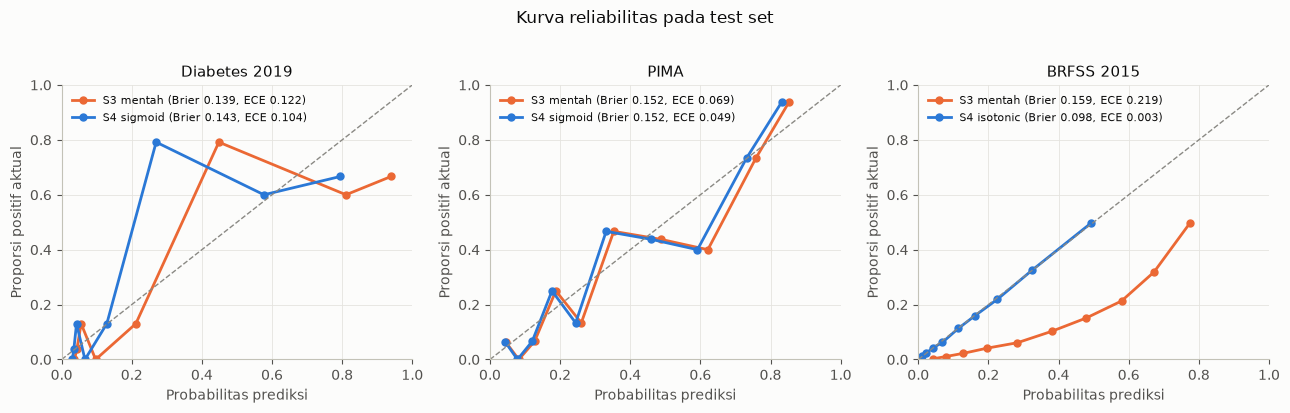

,Dataset,Model,Brier,ECE,Rata-rata prob. prediksi,Prevalensi aktual
0,Diabetes 2019,S3 mentah,0.1393,0.1220,0.3207,0.2888
1,Diabetes 2019,S4 sigmoid,0.1433,0.1039,0.2366,0.2888
2,PIMA,S3 mentah,0.1524,0.0690,0.3781,0.3506
3,PIMA,S4 sigmoid,0.1515,0.0488,0.3616,0.3506
4,BRFSS 2015,S3 mentah,0.1594,0.2194,0.3613,0.1419
5,BRFSS 2015,S4 isotonic,0.0979,0.0031,0.1429,0.1419


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
cal_rows = []
for ax, (k, out) in zip(axes, RESULTS.items()):
    y_te = SPECS[k].y.iloc[out['te']].to_numpy()
    nb = 10 if k != 'diabetes2019' else 8
    for lbl, p, c in [('S3 mentah', out['R']['S3'].p_test, PALETTE[1]), (f"S4 {out['cal_method']}", out['R']['S4'].p_test, PALETTE[0])]:
        fy, fx = calibration_curve(y_te, p, n_bins=nb, strategy='quantile')
        ax.plot(fx, fy, marker='o', ms=5, color=c, label=f'{lbl} (Brier {brier_score_loss(y_te, p):.3f}, ECE {ece_score(y_te, p):.3f})')
        cal_rows.append({'Dataset': TITLE[k], 'Model': lbl, 'Brier': brier_score_loss(y_te, p), 'ECE': ece_score(y_te, p),
                         'Rata-rata prob. prediksi': p.mean(), 'Prevalensi aktual': y_te.mean()})
    ax.plot([0, 1], [0, 1], ls='--', lw=1, color='#8a8984')
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Probabilitas prediksi', ylabel='Proporsi positif aktual', title=TITLE[k])
    ax.legend(fontsize=8, loc='upper left')
fig.suptitle('Kurva reliabilitas pada test set', y=1.02)
fig.tight_layout()
savefig(fig, 'fig04_reliability')
CALIB_TABLE = pd.DataFrame(cal_rows); display(CALIB_TABLE)

## 9. Analisis Seleksi Fitur Berbasis SHAP (H2)
* Fitur terpilih oleh `SHAPSelector` pada model final (di-*fit* pada seluruh data latih).
* Kurva performa vs jumlah fitur *k* (eksploratif; urutan fitur dari model final, sehingga sedikit optimistis).
* Latensi inferensi per pasien (rata-rata 200 prediksi satu-baris) untuk pipeline S2 (semua fitur) vs S3 (fitur terpilih).

In [15]:
sel_rows = []
for k, out in RESULTS.items():
    s3 = out['R']['S3'].extras['model']; sel = s3.named_steps['select']
    sel_rows.append({'Dataset': TITLE[k], 'k terpilih': sel.k_, 'p total': SPECS[k].X.shape[1],
                     'Reduksi input (%)': 100 * (1 - sel.k_ / SPECS[k].X.shape[1]),
                     'Fitur terpilih': ', '.join(sel.importances_.index[:sel.k_])})
SELECTION = pd.DataFrame(sel_rows)
with pd.option_context('display.max_colwidth', 400):
    display(SELECTION)

def latency_ms(pipe, X, n=200):
    """Median latensi end-to-end (imputasi → seleksi → XGBoost) untuk satu pasien."""
    rows = [X.iloc[[i]] for i in np.random.RandomState(SEED).choice(len(X), min(n, len(X)), replace=False)]
    for r in rows[:10]:
        pipe.predict_proba(r)          # pemanasan
    times = []
    for r in rows:
        t0 = time.perf_counter(); pipe.predict_proba(r); times.append(time.perf_counter() - t0)
    return float(np.median(times) * 1000)

lat_rows = []
for k, out in RESULTS.items():
    X_te = SPECS[k].X.iloc[out['te']]
    for s in ['S2', 'S3']:
        r = out['R'][s]
        lat_rows.append({'Dataset': TITLE[k], 'Skenario': s, 'n fitur': n_features(r, k), 'F1 test': r.test['F1'],
                         'F1 CV (mean)': r.cv['F1'].mean(), 'AUPRC test': r.test['AUPRC'],
                         'Latensi/pasien (ms)': latency_ms(r.extras['model'], X_te)})
LATENCY = pd.DataFrame(lat_rows); display(LATENCY)

,Dataset,k terpilih,p total,Reduksi input (%),Fitur terpilih
0,Diabetes 2019,10,17,41.1765,"RegularMedicine, Age, SoundSleep, BPLevel, Family_Diabetes, PhysicallyActive, Stress, BMI, Sleep, Pregancies"
1,PIMA,6,8,25.0000,"Glucose, BMI, Age, DiabetesPedigreeFunction, Pregnancies, Insulin"
2,BRFSS 2015,6,21,71.4286,"GenHlth, HighBP, BMI, Age, HighChol, Income"


,Dataset,Skenario,n fitur,F1 test,F1 CV (mean),AUPRC test,Latensi/pasien (ms)
0,Diabetes 2019,S2,17,0.6727,0.6880,0.6893,4.8440
1,Diabetes 2019,S3,10,0.7288,0.6857,0.7023,4.3580
2,PIMA,S2,8,0.6329,0.6517,0.7755,2.4122
3,PIMA,S3,6,0.6533,0.6736,0.7674,2.8667
4,BRFSS 2015,S2,21,0.4328,0.4311,0.4402,5.0693
5,BRFSS 2015,S3,6,0.4297,0.4277,0.4353,5.4775


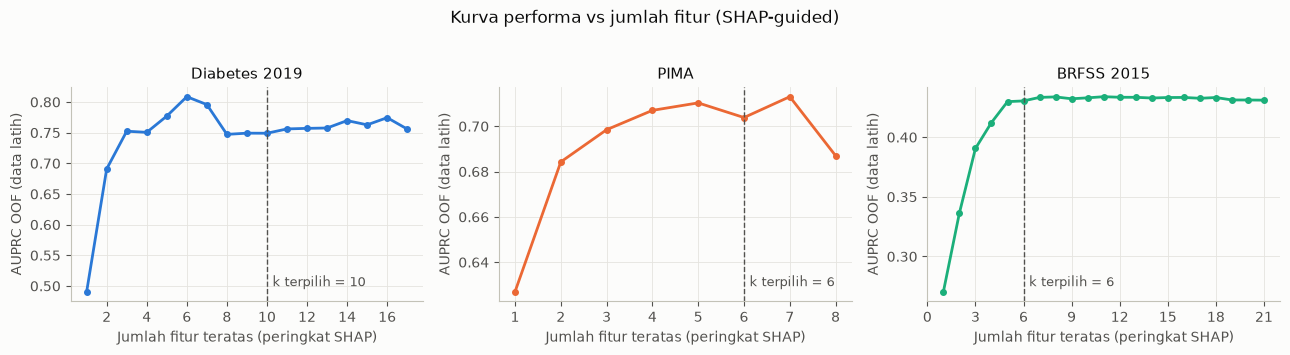

In [16]:
def k_curve(spec, out, max_rows=None, n_folds=None):
    tr = out['tr']; t = out['tuning']['S2']
    ranking = list(out['R']['S3'].extras['model'].named_steps['select'].importances_.index)
    X_tr, y_tr, g_tr = spec.X.iloc[tr], spec.y.iloc[tr], spec.groups[tr]
    if max_rows and len(tr) > max_rows:
        sub, _ = train_test_split(np.arange(len(tr)), train_size=max_rows, stratify=y_tr, random_state=SEED)
        X_tr, y_tr, g_tr = X_tr.iloc[sub], y_tr.iloc[sub], g_tr[sub]
    folds = make_folds(y_tr, g_tr, n_folds or N_FOLDS, 'group')
    rows = []
    for kk in range(1, len(ranking) + 1):
        cols = ranking[:kk]
        sub_spec = DatasetSpec(spec.key, X_tr[cols], y_tr, g_tr, spec.sampler,
                               [c for c in spec.categorical if c in cols], [c for c in spec.discrete if c in cols])
        oof = oof_predict(lambda: build_pipeline(sub_spec, t['xgb_params'], t['spw_mult'], t['sampling']), X_tr[cols], y_tr, folds)
        rows.append({'k': kk, 'AUPRC': average_precision_score(y_tr, oof), 'ROC_AUC': roc_auc_score(y_tr, oof)})
    return pd.DataFrame(rows)

KCURVE = {k: k_curve(SPECS[k], RESULTS[k], max_rows=(None if k != 'brfss' else (6_000 if FAST_MODE else 40_000)),
                     n_folds=(None if k != 'brfss' else 3)) for k in SPECS}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (k, kc) in zip(axes, KCURVE.items()):
    ksel = RESULTS[k]['R']['S3'].extras['model'].named_steps['select'].k_
    ax.plot(kc['k'], kc['AUPRC'], marker='o', ms=4, color=DS_COLOR[k])
    ax.axvline(ksel, ls='--', lw=1, color=TEXT2)
    ax.annotate(f'k terpilih = {ksel}', (ksel, kc['AUPRC'].min()), xytext=(4, 4), textcoords='offset points', fontsize=9, color=TEXT2)
    ax.set(xlabel='Jumlah fitur teratas (peringkat SHAP)', ylabel='AUPRC OOF (data latih)', title=TITLE[k])
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
fig.suptitle('Kurva performa vs jumlah fitur (SHAP-guided)', y=1.03)
fig.tight_layout()
savefig(fig, 'fig05_shap_k_curve')

## 10. *Explainable AI*: SHAP Global dan Lokal
SHAP (TreeExplainer) menjelaskan *margin* (log-odds) XGBoost final S3; kalibrasi S4 adalah transformasi monoton sehingga urutan risiko dan arah kontribusi fitur tetap sama. Nilai fitur ditampilkan dalam satuan klinis asli karena model dilatih tanpa *scaling* (scaler hanya dipakai di dalam *resampler*).

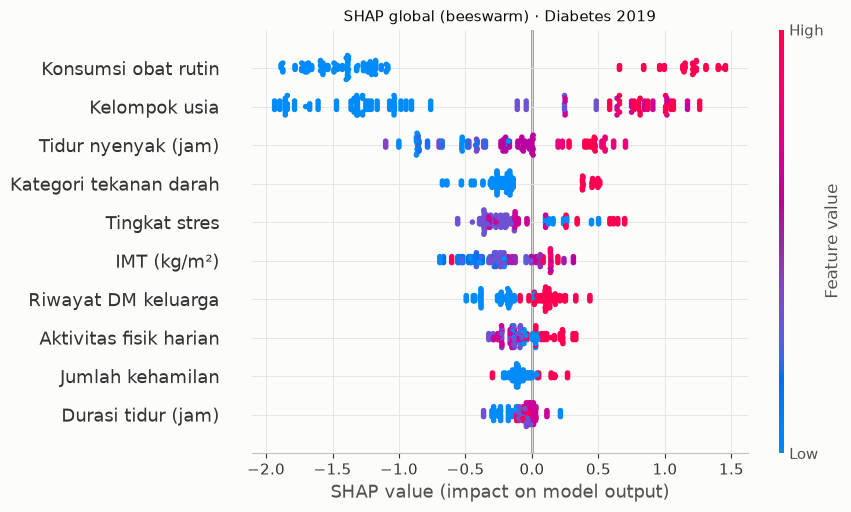

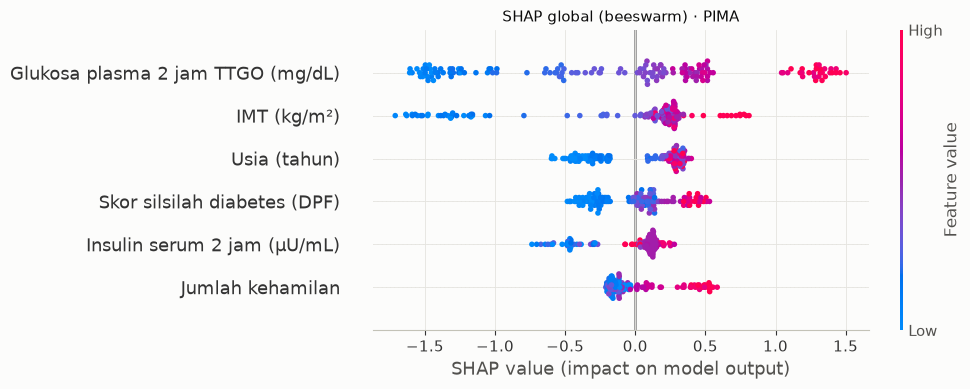

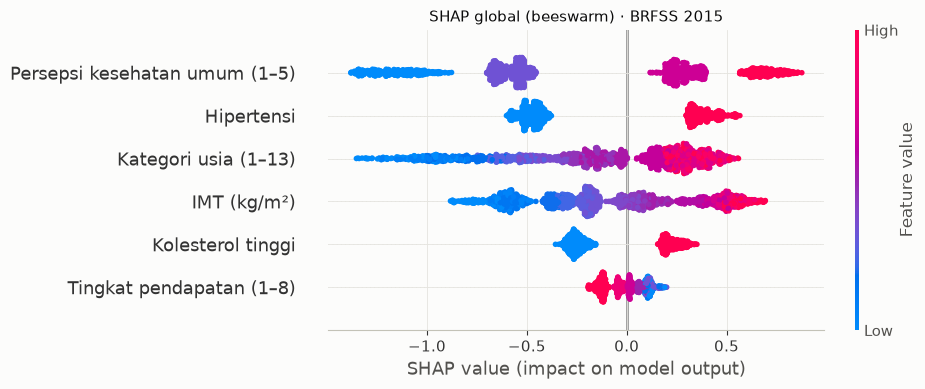

In [17]:
def explain(k, n_max=2000):
    out = RESULTS[k]; model = out['R']['S3'].extras['model']
    Xt = transform_features(model, SPECS[k].X.iloc[out['te']])
    Xs = Xt.sample(min(len(Xt), n_max), random_state=SEED) if len(Xt) > n_max else Xt
    explainer = shap.TreeExplainer(model.named_steps['clf'].model_)
    ex = explainer(Xs)
    ex.feature_names = [LABEL[k][c] for c in Xs.columns]
    return explainer, ex, Xs

EXPL = {k: explain(k) for k in SPECS}
for k, (_, ex, Xs) in EXPL.items():
    plt.figure()
    shap.plots.beeswarm(ex, max_display=12, show=False)
    plt.title(f'SHAP global (beeswarm) · {TITLE[k]}', fontsize=11)
    savefig(plt.gcf(), f'fig06_shap_beeswarm_{k}')

,Dataset,Peringkat,Fitur,Label,mean|SHAP|,Konsep klinis,Faktor risiko mapan
0,Diabetes 2019,1,RegularMedicine,Konsumsi obat rutin,1.3556,Penggunaan obat,False
1,Diabetes 2019,2,Age,Kelompok usia,1.0786,Usia,True
2,Diabetes 2019,3,SoundSleep,Tidur nyenyak (jam),0.4346,Gaya hidup lain,False
3,Diabetes 2019,4,BPLevel,Kategori tekanan darah,0.2960,Hipertensi,True
4,Diabetes 2019,5,Stress,Tingkat stres,0.2904,Gaya hidup lain,False
10,PIMA,1,Glucose,Glukosa plasma 2 jam TTGO (mg/dL),0.7952,Glikemia/gejala hiperglikemia,True
11,PIMA,2,BMI,IMT (kg/m²),0.4841,Adipositas,True
12,PIMA,3,Age,Usia (tahun),0.3097,Usia,True
13,PIMA,4,DiabetesPedigreeFunction,Skor silsilah diabetes (DPF),0.2402,Riwayat keluarga/genetik,True
14,PIMA,5,Insulin,Insulin serum 2 jam (µU/mL),0.1975,Glikemia/gejala hiperglikemia,True


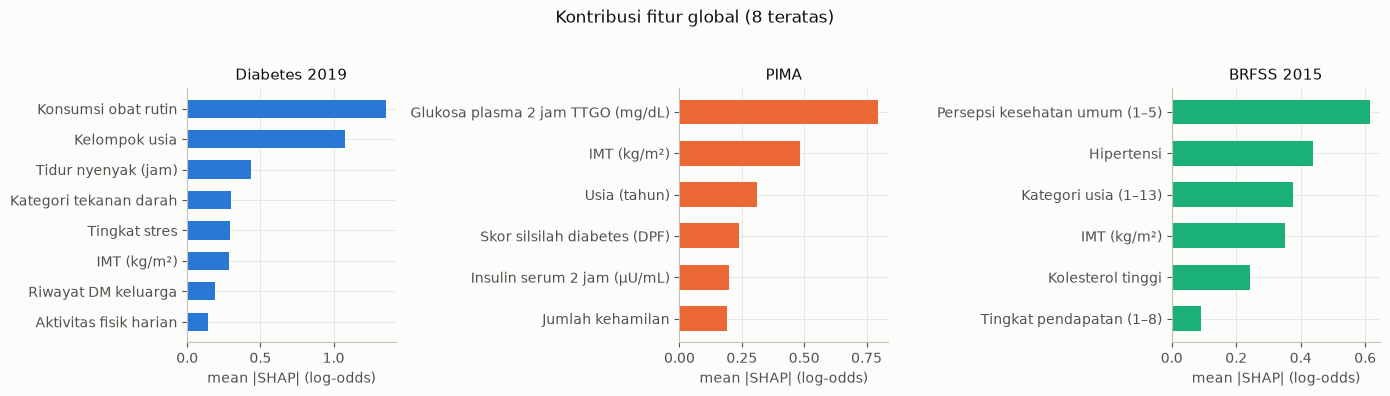

In [18]:
glob_rows = []
for k, (_, ex, Xs) in EXPL.items():
    imp = pd.Series(np.abs(ex.values).mean(0), index=Xs.columns).sort_values(ascending=False)
    for rank, (c, v) in enumerate(imp.items(), 1):
        glob_rows.append({'Dataset': TITLE[k], 'Peringkat': rank, 'Fitur': c, 'Label': LABEL[k][c], 'mean|SHAP|': v,
                          'Konsep klinis': META[k][c]['concept'], 'Faktor risiko mapan': META[k][c]['concept'] in ESTABLISHED})
GLOBAL_SHAP = pd.DataFrame(glob_rows)
display(GLOBAL_SHAP[GLOBAL_SHAP['Peringkat'] <= 5])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (k, (_, ex, Xs)) in zip(axes, EXPL.items()):
    g = GLOBAL_SHAP[GLOBAL_SHAP['Dataset'] == TITLE[k]].head(8).iloc[::-1]
    ax.barh(g['Label'], g['mean|SHAP|'], color=DS_COLOR[k], height=0.6)
    ax.set(title=TITLE[k], xlabel='mean |SHAP| (log-odds)')
fig.suptitle('Kontribusi fitur global (8 teratas)', y=1.03)
fig.tight_layout()
savefig(fig, 'fig07_shap_global_bar')

### 10.1 Penjelasan lokal (*waterfall*) dan konsistensi klinis (H4)
Kriteria H4 (ditetapkan sebelum melihat hasil): untuk tiap dataset, (a) ≥3 dari 5 fitur global teratas merupakan faktor risiko mapan, dan (b) ≥60% slot top-3 penjelasan lokal (kontribusi positif terbesar) pada pasien yang diprediksi berisiko diisi faktor risiko mapan.

In [19]:
def local_consistency(k, top=3):
    out = RESULTS[k]; s4 = out['R']['S4']
    expl, ex, Xs = EXPL[k]
    model = out['R']['S3'].extras['model']
    Xt = transform_features(model, SPECS[k].X.iloc[out['te']])
    flagged = Xt.index[s4.p_test >= s4.thr]
    if len(flagged) > 3000:
        flagged = pd.Index(np.random.RandomState(SEED).choice(flagged, 3000, replace=False))
    sv = expl.shap_values(Xt.loc[flagged])
    cols = np.array(Xt.columns); counts = {}; established = 0; slots = 0
    for row in sv:
        order = np.argsort(-row)[:top]
        for j in order:
            if row[j] <= 0:
                continue
            counts[cols[j]] = counts.get(cols[j], 0) + 1
            slots += 1; established += META[k][cols[j]]['concept'] in ESTABLISHED
    freq = (pd.Series(counts).sort_values(ascending=False) / len(flagged) * 100).rename('% pasien berisiko')
    return freq, established / max(slots, 1), len(flagged)

H4_rows, LOCAL_FREQ = [], {}
for k in SPECS:
    freq, align, n = local_consistency(k)
    LOCAL_FREQ[k] = freq
    g5 = GLOBAL_SHAP[(GLOBAL_SHAP['Dataset'] == TITLE[k]) & (GLOBAL_SHAP['Peringkat'] <= 5)]
    H4_rows.append({'Dataset': TITLE[k], 'Pasien diprediksi berisiko (dianalisis)': n,
                    'Top-5 global yang faktor risiko mapan': int(g5['Faktor risiko mapan'].sum()),
                    'Rasio keselarasan lokal top-3': align,
                    'Fitur terbanyak di top-3 lokal': ', '.join(f'{LABEL[k][c]} ({v:.0f}%)' for c, v in freq.head(4).items())})
H4_TABLE = pd.DataFrame(H4_rows); display(H4_TABLE)

,Dataset,Pasien diprediksi berisiko (dianalisis),Top-5 global yang faktor risiko mapan,Rasio keselarasan lokal top-3,Fitur terbanyak di top-3 lokal
0,Diabetes 2019,64,2,0.5778,"Kelompok usia (81%), Konsumsi obat rutin (69%)..."
1,PIMA,96,5,0.9184,"IMT (kg/m²) (75%), Glukosa plasma 2 jam TTGO (..."
2,BRFSS 2015,3000,4,0.7199,"Hipertensi (78%), Persepsi kesehatan umum (1–5..."


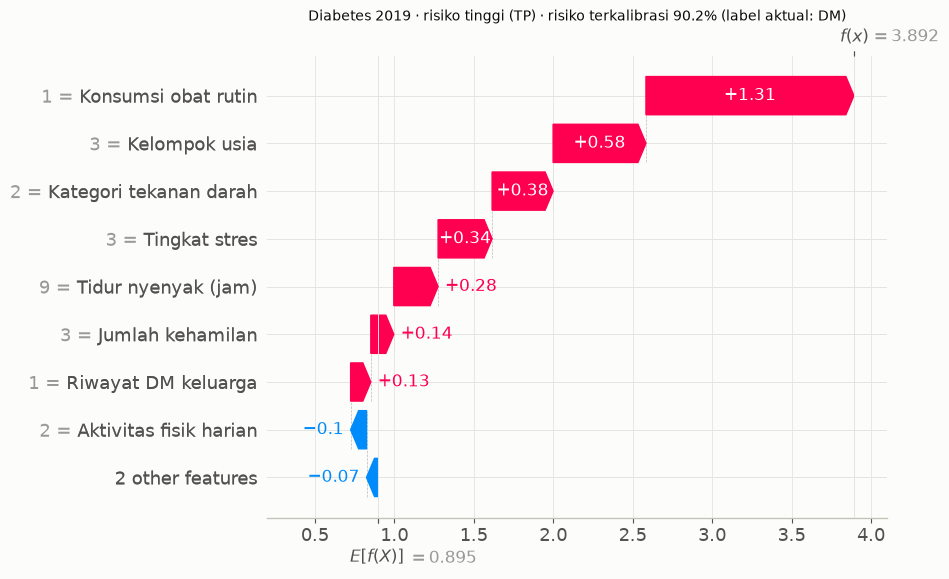

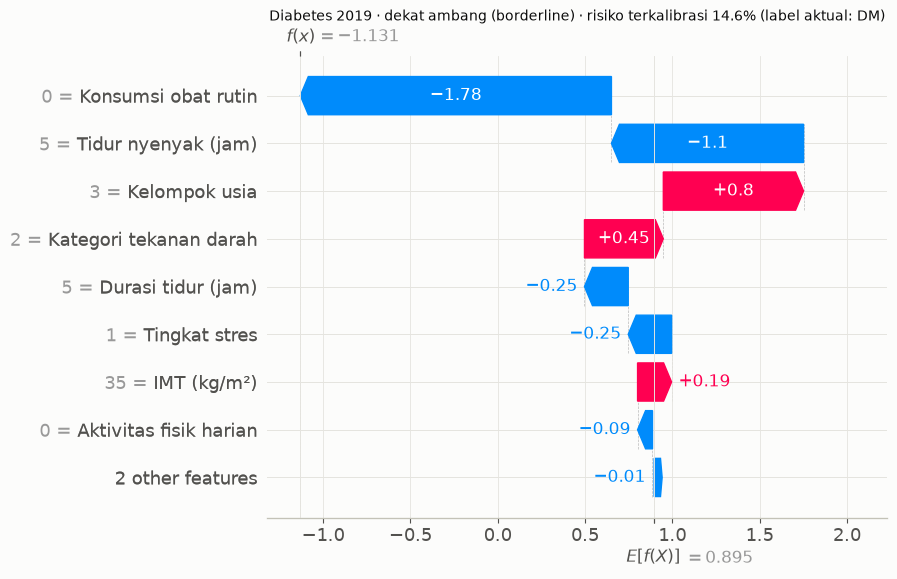

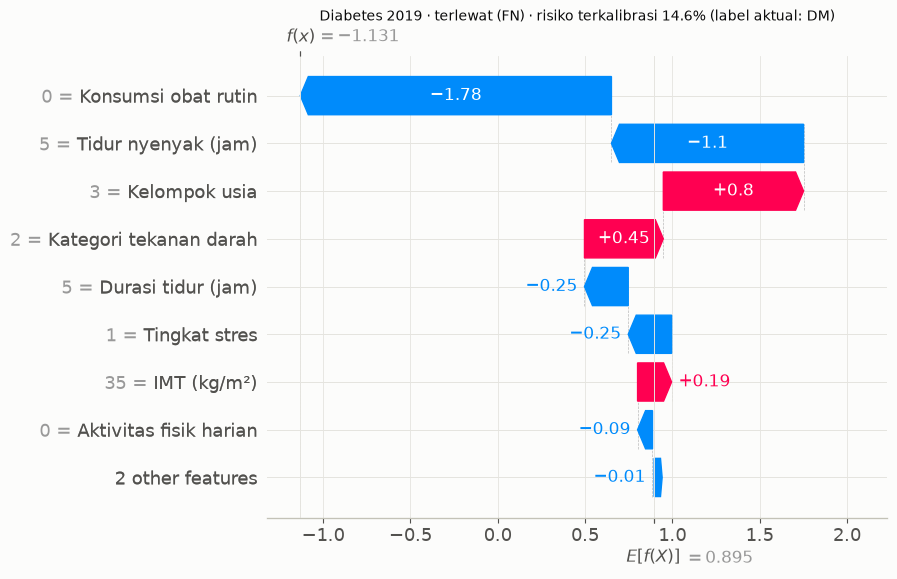

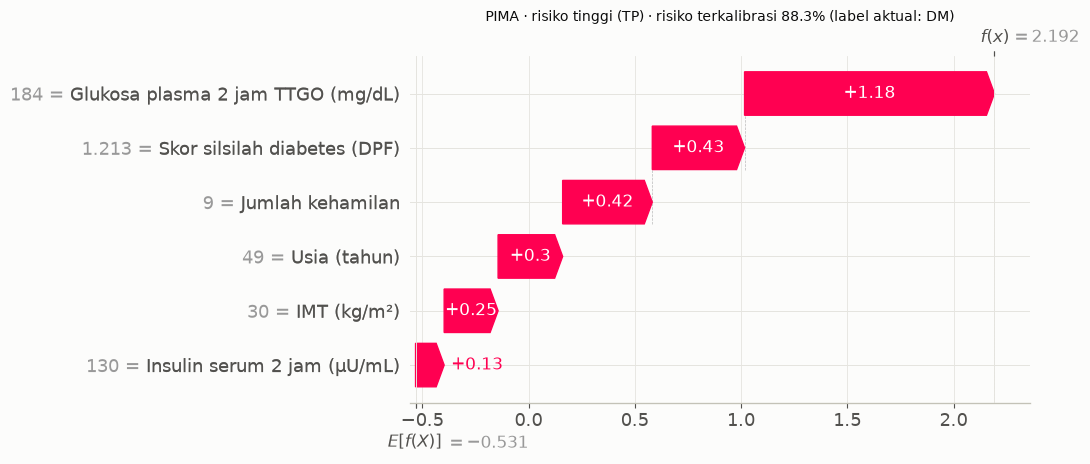

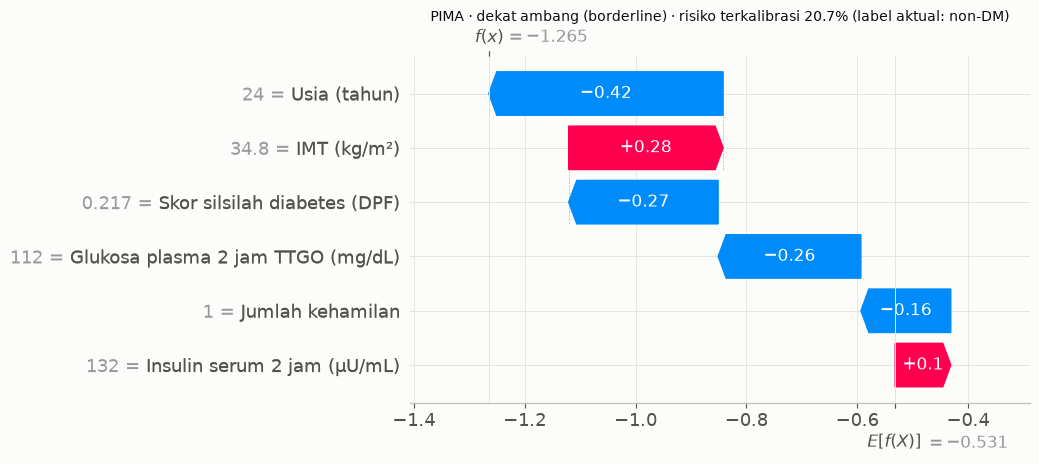

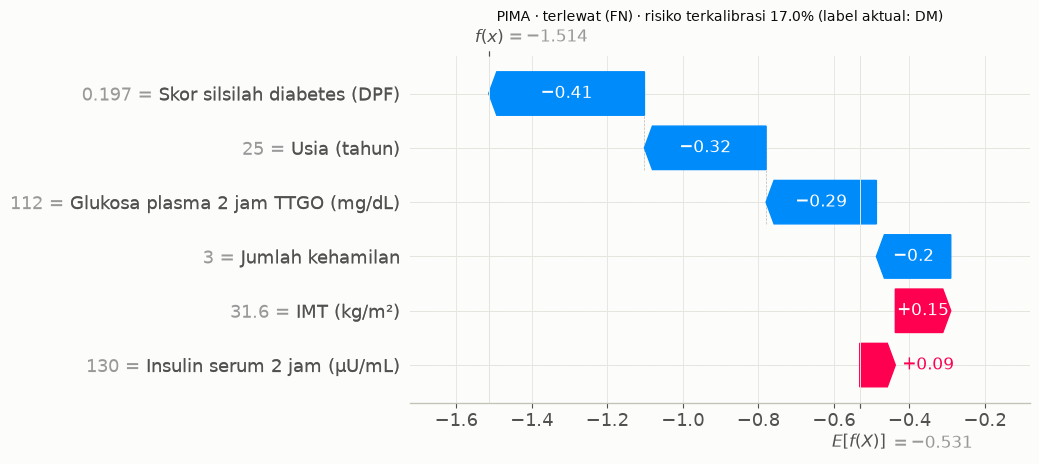

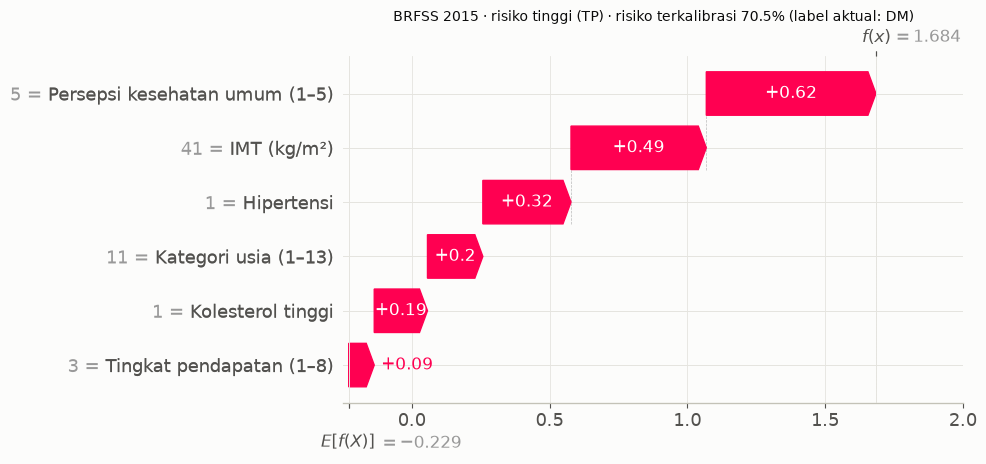

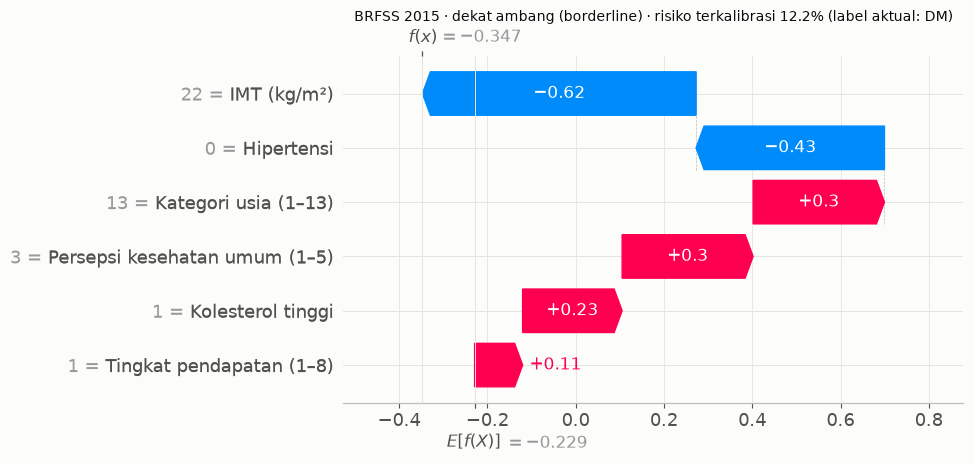

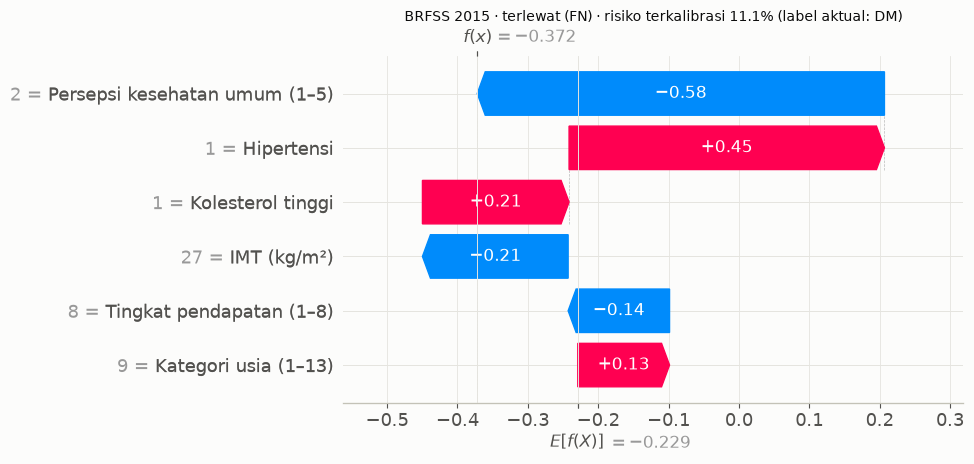

In [20]:
def pick_cases(k):
    out = RESULTS[k]; s4 = out['R']['S4']; y_te = SPECS[k].y.iloc[out['te']].to_numpy(); p = s4.p_test
    tp = np.where((y_te == 1) & (p >= s4.thr))[0]; fn = np.where((y_te == 1) & (p < s4.thr))[0]
    cases = {'risiko tinggi (TP)': tp[np.argmax(p[tp])] if len(tp) else None,
             'dekat ambang (borderline)': int(np.argmin(np.abs(p - s4.thr))),
             'terlewat (FN)': fn[np.argmax(p[fn])] if len(fn) else None}
    return {c: i for c, i in cases.items() if i is not None}

CASES = {}
for k in SPECS:
    out = RESULTS[k]; model = out['R']['S3'].extras['model']; expl = EXPL[k][0]
    Xt = transform_features(model, SPECS[k].X.iloc[out['te']])
    for case, i in pick_cases(k).items():
        e = expl(Xt.iloc[[i]])[0]; e.feature_names = [LABEL[k][c] for c in Xt.columns]
        p = out['R']['S4'].p_test[i]; yt = int(SPECS[k].y.iloc[out['te']].iloc[i])
        CASES[(k, case)] = {'p': p, 'y': yt}
        plt.figure()
        shap.plots.waterfall(e, max_display=9, show=False)
        plt.title(f'{TITLE[k]} · {case} · risiko terkalibrasi {p*100:.1f}% (label aktual: {"DM" if yt else "non-DM"})', fontsize=10)
        savefig(plt.gcf(), f'fig08_waterfall_{k}_{case.split()[0]}')

## 11. Sensitivitas Protokol: *Split* Acak (Gaya Literatur) vs *Leakage-Free*, dan Deduplikasi
Hiperparameter hasil *tuning* protokol utama dipakai ulang (tanpa *tuning* ulang) agar yang berubah hanya protokol pemisahan/deduplikasi. Untuk tiap protokol dilaporkan S0 (baseline) dan S4 (model lengkap) pada test set masing-masing.

Analisis tambahan (eksploratif, dipicu oleh temuan SHAP): model Diabetes 2019 **tanpa `RegularMedicine`**, karena konsumsi obat rutin dapat merupakan akibat dari diagnosis (*reverse causation*), bukan prediktor yang tersedia saat skrining dini.

In [21]:
def run_protocol_variant(k, X, y, groups, protocol, label):
    spec0 = SPECS[k]
    spec = DatasetSpec(k, X.reset_index(drop=True), y.reset_index(drop=True), np.asarray(groups), spec0.sampler,
                       spec0.categorical, spec0.discrete)
    tr, te = split_indices(spec.y, spec.groups, protocol)
    folds = make_folds(spec.y.iloc[tr], spec.groups[tr], N_FOLDS, protocol)
    t = RESULTS[k]['tuning']['S2']
    print(f'-- {TITLE[k]} · {label} (n={len(y)})')
    s0 = run_scenario('S0', spec, tr, te, folds, lambda: build_pipeline(spec), tune_threshold=False)
    s3 = run_scenario('S3', spec, tr, te, folds, lambda: build_pipeline(spec, t['xgb_params'], t['spw_mult'], t['sampling'], select=True))
    s4 = run_calibrated('S4', s3, spec, tr, te, folds, RESULTS[k]['cal_method'])
    leak = leakage_audit(spec.X, tr, te, near=(k == 'diabetes2019'))
    return [{'Dataset': TITLE[k], 'Protokol': label, 'Skenario': s, 'n total': len(y), 'n uji': len(te),
             'Prevalensi uji': spec.y.iloc[te].mean(), **leak, **{m: r.test[m] for m in MAIN + ['BalancedAcc', 'MacroF1', 'WeightedF1', 'GMean']}}
            for s, r in [('S0', s0), ('S4', s4)]], {'S0': s0, 'S4': s4, 'tr': tr, 'te': te, 'spec': spec}

PROTO_ROWS, PROTO_RES = [], {}
for k in SPECS:
    s = SPECS[k]
    for s_name in ['S0', 'S4']:
        r = RESULTS[k]['R'][s_name]
        PROTO_ROWS.append({'Dataset': TITLE[k], 'Protokol': 'group-aware (utama)', 'Skenario': s_name, 'n total': len(s.y),
                           'n uji': len(RESULTS[k]['te']), 'Prevalensi uji': s.y.iloc[RESULTS[k]['te']].mean(),
                           **leakage_audit(s.X, RESULTS[k]['tr'], RESULTS[k]['te'], near=(k == 'diabetes2019')),
                           **{m: r.test[m] for m in MAIN + ['BalancedAcc', 'MacroF1', 'WeightedF1', 'GMean']}})
for k in ['diabetes2019', 'brfss']:
    s = SPECS[k]
    rows, PROTO_RES[(k, 'random')] = run_protocol_variant(k, s.X, s.y, s.groups, 'random', 'acak (literatur), tanpa dedup')
    PROTO_ROWS += rows
X_dd19 = pd.concat([X19, y19], axis=1).drop_duplicates()
rows, PROTO_RES[('diabetes2019', 'dedup')] = run_protocol_variant('diabetes2019', X_dd19.drop(columns='y'), X_dd19['y'],
                                                                  np.arange(len(X_dd19)), 'random', 'dedup persis + acak')
PROTO_ROWS += rows
Xbd, ybd, gbd, _ = clean_brfss(RAW['brfss'], dedup=True, max_rows=BRFSS_MAX_ROWS)
rows, PROTO_RES[('brfss', 'dedup')] = run_protocol_variant('brfss', Xbd, ybd, gbd, 'random', 'dedup + acak')
PROTO_ROWS += rows
# PIMA: tidak ada duplikat → protokol acak identik secara distribusi dengan group-aware (grup = baris)
rows, PROTO_RES[('pima', 'random')] = run_protocol_variant('pima', SPECS['pima'].X, SPECS['pima'].y, SPECS['pima'].groups,
                                                           'random', 'acak (literatur)')
PROTO_ROWS += rows
# Analisis eksploratif yang dipicu SHAP (Bagian 10): RegularMedicine (konsumsi obat rutin) menjadi kontributor global
# teratas pada Diabetes 2019. Fitur ini dapat mencerminkan pengobatan SETELAH diagnosis (reverse causation), sehingga
# tidak valid untuk skrining dini. Uji: model lengkap tanpa fitur tersebut (protokol group-aware, hiperparameter sama).
_s19 = SPECS['diabetes2019']
rows, PROTO_RES[('diabetes2019', 'nomed')] = run_protocol_variant('diabetes2019', _s19.X.drop(columns='RegularMedicine'), _s19.y,
                                                                  _s19.groups, 'group', 'group-aware, tanpa RegularMedicine')
PROTO_ROWS += rows
PROTOCOL_TABLE = pd.DataFrame(PROTO_ROWS)
display(PROTOCOL_TABLE[['Dataset', 'Protokol', 'Skenario', 'n total', 'n uji', 'Prevalensi uji'] +
                       [c for c in PROTOCOL_TABLE.columns if c.startswith('%')] + MAIN])
PROTOCOL_TABLE.to_csv(OUT / 'protocol_sensitivity.csv', index=False)
_v = PROTO_RES[('diabetes2019', 'nomed')]; _m = _v['S4'].extras['model']
_Xt = transform_features(_m, _v['spec'].X.iloc[_v['te']])
NOMED_TOP = pd.Series(np.abs(shap.TreeExplainer(_m.named_steps['clf'].model_).shap_values(_Xt)).mean(0),
                      index=_Xt.columns).sort_values(ascending=False)
print('Diabetes 2019 tanpa RegularMedicine → fitur SHAP teratas:',
      {LABEL['diabetes2019'][c]: round(float(v), 3) for c, v in NOMED_TOP.head(6).items()})

-- Diabetes 2019 · acak (literatur), tanpa dedup (n=951)
   S0      selesai dalam    0.9 dtk | test: Recall=0.887 Spec=1.000 F1=0.940 AUPRC=0.964 Brier=0.0300
   S3      selesai dalam    3.3 dtk | test: Recall=0.943 Spec=0.913 F1=0.870 AUPRC=0.976 Brier=0.0565
   S4      kalibrasi sigmoid | test: Recall=0.943 Spec=0.913 F1=0.870 AUPRC=0.976 Brier=0.0373
-- BRFSS 2015 · acak (literatur), tanpa dedup (n=249049)
   S0      selesai dalam    6.6 dtk | test: Recall=0.199 Spec=0.975 F1=0.294 AUPRC=0.441 Brier=0.0975
   S3      selesai dalam   32.9 dtk | test: Recall=0.838 Spec=0.664 F1=0.433 AUPRC=0.435 Brier=0.1578
   S4      kalibrasi isotonic | test: Recall=0.838 Spec=0.664 F1=0.433 AUPRC=0.430 Brier=0.0980
-- Diabetes 2019 · dedup persis + acak (n=301)
   S0      selesai dalam    0.8 dtk | test: Recall=0.667 Spec=0.860 F1=0.667 AUPRC=0.714 Brier=0.1820
   S3      selesai dalam    2.7 dtk | test: Recall=0.944 Spec=0.535 F1=0.618 AUPRC=0.708 Brier=0.1530
   S4      kalibrasi sigmoid | test:

,Dataset,Protokol,Skenario,n total,n uji,Prevalensi uji,% uji dgn salinan persis di latih,% uji dgn salinan ≤1 fitur di latih,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,AUPRC,Brier,FNR
0,Diabetes 2019,group-aware (utama),S0,951,187,0.2888,0.0000,0.0000,0.7968,0.6818,0.5556,0.8947,0.6122,0.8473,0.7191,0.1725,0.4444
1,Diabetes 2019,group-aware (utama),S4,951,187,0.2888,0.0000,0.0000,0.8289,0.6719,0.7963,0.8421,0.7288,0.8661,0.7023,0.1433,0.2037
2,PIMA,group-aware (utama),S0,768,154,0.3506,0.0000,NaN,0.7403,0.6400,0.5926,0.8200,0.6154,0.7746,0.6744,0.2151,0.4074
3,PIMA,group-aware (utama),S4,768,154,0.3506,0.0000,NaN,0.6623,0.5104,0.9074,0.5300,0.6533,0.8429,0.7674,0.1515,0.0926
4,BRFSS 2015,group-aware (utama),S0,249049,49810,0.1419,0.0000,NaN,0.8647,0.5680,0.1944,0.9756,0.2896,0.8325,0.4396,0.0975,0.8056
5,BRFSS 2015,group-aware (utama),S4,249049,49810,0.1419,0.0000,NaN,0.6807,0.2872,0.8435,0.6537,0.4285,0.8290,0.4282,0.0979,0.1565
6,Diabetes 2019,"acak (literatur), tanpa dedup",S0,951,191,0.2775,94.7644,100.0000,0.9686,1.0000,0.8868,1.0000,0.9400,0.9772,0.9642,0.0300,0.1132
7,Diabetes 2019,"acak (literatur), tanpa dedup",S4,951,191,0.2775,94.7644,100.0000,0.9215,0.8065,0.9434,0.9130,0.8696,0.9889,0.9764,0.0373,0.0566
8,BRFSS 2015,"acak (literatur), tanpa dedup",S0,249049,49810,0.1419,13.6740,NaN,0.8645,0.5643,0.1986,0.9746,0.2938,0.8334,0.4413,0.0975,0.8014
9,BRFSS 2015,"acak (literatur), tanpa dedup",S4,249049,49810,0.1419,13.6740,NaN,0.6889,0.2922,0.8377,0.6643,0.4332,0.8304,0.4297,0.0980,0.1623


Diabetes 2019 tanpa RegularMedicine → fitur SHAP teratas: {'Kelompok usia': 1.675, 'Kategori tekanan darah': 0.505, 'Tingkat stres': 0.451, 'Tidur nyenyak (jam)': 0.309, 'Riwayat DM keluarga': 0.264, 'IMT (kg/m²)': 0.256}


## 12. Komparasi dengan Lima Paper Rujukan
Angka paper disalin dari tabel/teks aslinya (sumber dicantumkan per baris). **Perhatikan kolom protokol**: beberapa angka berasal dari protokol yang bocor (SMOTE/undersampling sebelum *split*, CV pada data hasil SMOTE) atau dari test set yang diseimbangkan, sehingga tidak dapat dibandingkan secara langsung dengan angka kami pada test set berprevalensi alami. Untuk Zhang et al. (test set seimbang 50:50), metrik yang setara adalah sensitivitas, spesifisitas, dan **balanced accuracy** kami.

In [22]:
NA = np.nan
LIT = [
    # dataset, paper, model, protokol, Acc, Prec, Rec, Spec, F1, AUC, AUPRC, sumber
    ('diabetes2019', 'Uddin et al. (2024)', 'Random Forest', 'SMOTE sebelum split; 70:30', 0.9754, NA, NA, NA, NA, NA, NA, 'Tabel 3'),
    ('diabetes2019', 'Mahajan et al. (2024)', 'XGBoost', 'train/val/test; GridSearch 5-fold', 0.85, 0.82, 0.85, NA, 0.82, 0.85, 0.69, 'Tabel 3–13 (D10)'),
    ('diabetes2019', 'Mahajan et al. (2024)', 'Classic Stacking', 'train/val/test; GridSearch 5-fold', 0.97, 0.97, 0.97, NA, 0.97, 0.94, 0.86, 'Tabel 3–13 (D10)'),
    ('diabetes2019', 'Pan et al. (2026)', 'TEA-CGAN + RF', 'protokol split tidak dilaporkan', NA, NA, NA, NA, 0.8687, 0.9618, NA, 'Tabel 2 (G-mean 0,9151)'),
    ('diabetes2019', 'Pan et al. (2026)', 'Borderline-SMOTE + RF', 'protokol split tidak dilaporkan', NA, NA, NA, NA, 0.7968, 0.9517, NA, 'Tabel 2 (G-mean 0,8724)'),
    ('diabetes2019', 'Zhang et al. (2024)', 'DiabetesNet (BPNN)', 'undersampling sebelum split; test 50:50', 0.9528, NA, 1.0, 0.9219, NA, NA, NA, 'Tabel 2 (BIT Mesra)'),
    ('diabetes2019', 'Zhang et al. (2024)', 'XGBoost', 'undersampling sebelum split; test 50:50', 0.9245, NA, 0.9524, 0.9062, NA, NA, NA, 'Tabel 2 (BIT Mesra)'),
    ('pima', 'Uddin et al. (2024)', 'Random Forest', 'SMOTE sebelum split; 75:25', 0.79, NA, NA, NA, NA, NA, NA, 'Tabel 4 (abstrak: 80%)'),
    ('pima', 'Mahajan et al. (2024)', 'XGBoost', 'train/val/test; GridSearch 5-fold', 0.72, 0.73, 0.72, NA, 0.72, 0.71, 0.52, 'Tabel 3–13 (D9)'),
    ('pima', 'Mahajan et al. (2024)', 'Two-Level Stacking', 'train/val/test; GridSearch 5-fold', 0.80, 0.80, 0.80, NA, 0.80, 0.81, 0.59, 'Tabel 3–13 (D9)'),
    ('pima', 'Asif et al. (2025)', 'XGBoost', 'hold-out unseen (6 fitur RFE)', 0.7532, 0.6232, 0.7818, NA, 0.6935, NA, NA, 'Tabel 29'),
    ('pima', 'Asif et al. (2025)', 'Random Forest', 'hold-out unseen (6 fitur RFE)', 0.7727, 0.6515, 0.7818, NA, 0.7107, NA, NA, 'Tabel 29'),
    ('pima', 'Zhang et al. (2024)', 'DiabetesNet (BPNN)', 'undersampling sebelum split; test 50:50', 0.8981, NA, 0.8929, 0.9038, NA, NA, NA, 'Tabel 2'),
    ('pima', 'Zhang et al. (2024)', 'XGBoost', 'undersampling sebelum split; test 50:50', 0.7870, NA, 0.7377, 0.8511, NA, NA, NA, 'Tabel 2'),
    ('brfss', 'Asif et al. (2025)', 'CatBoost (top-15)', 'CV 5-fold pada data ber-SMOTE', 0.9197, 0.9247, 0.9198, NA, 0.9195, NA, NA, 'Tabel 18 (rata-rata berbobot)'),
    ('brfss', 'Asif et al. (2025)', 'CatBoost (top-15)', 'test unseen, SMOTE hanya latih; 70:30', 0.8630, 0.7187, 0.5869, NA, 0.6094, NA, NA, 'Tabel 19 (rata-rata makro)'),
    ('brfss', 'Asif et al. (2025)', 'XGBoost (top-15)', 'test unseen; 70:30', 0.8655, 0.8380, 0.8655, NA, 0.8397, NA, NA, 'Tabel 21 (rata-rata berbobot)'),
    ('brfss', 'Zhang et al. (2024)', 'DiabetesNet (BPNN)', 'undersampling sebelum split; test 50:50', 0.7549, NA, 0.7977, 0.7112, NA, NA, NA, 'Tabel 2'),
    ('brfss', 'Zhang et al. (2024)', 'XGBoost', 'undersampling sebelum split; test 50:50', 0.7505, NA, 0.7987, 0.7017, NA, NA, NA, 'Tabel 2'),
]
cols = ['key', 'Studi', 'Model', 'Protokol', 'Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'ROC_AUC', 'AUPRC', 'Sumber']
LIT_DF = pd.DataFrame(LIT, columns=cols)

def our_rows(k):
    rows = []
    for lbl, r, proto in [('S4 (utama)', RESULTS[k]['R']['S4'], 'group-aware 80:20; RS hanya latih; test prevalensi alami'),
                          ('S4 (protokol literatur)', PROTO_RES[(k, 'random')]['S4'], 'acak 80:20; RS hanya latih; test prevalensi alami')]:
        t = r.test
        rows.append({'key': k, 'Studi': 'Usulan (notebook ini)', 'Model': f'Tuned XGBoost + leakage-free balancing · {lbl}',
                     'Protokol': proto, **{m: t[m] for m in ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'ROC_AUC', 'AUPRC']},
                     'Sumber': f"BalancedAcc={t['BalancedAcc']:.4f}; MacroF1={t['MacroF1']:.4f}; WeightedF1={t['WeightedF1']:.4f}; GMean={t['GMean']:.4f}; Brier={t['Brier']:.4f}"})
    return rows

SOTA = pd.concat([LIT_DF, pd.DataFrame([row for k in SPECS for row in our_rows(k)])], ignore_index=True)
for k in SPECS:
    print(f'\n### {TITLE[k]}')
    with pd.option_context('display.max_colwidth', 120):
        display(SOTA[SOTA['key'] == k].drop(columns='key'))
SOTA.to_csv(OUT / 'sota_comparison.csv', index=False)


### Diabetes 2019


,Studi,Model,Protokol,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,AUPRC,Sumber
0,Uddin et al. (2024),Random Forest,SMOTE sebelum split; 70:30,0.9754,NaN,NaN,NaN,NaN,NaN,NaN,Tabel 3
1,Mahajan et al. (2024),XGBoost,train/val/test; GridSearch 5-fold,0.8500,0.8200,0.8500,NaN,0.8200,0.8500,0.6900,Tabel 3–13 (D10)
2,Mahajan et al. (2024),Classic Stacking,train/val/test; GridSearch 5-fold,0.9700,0.9700,0.9700,NaN,0.9700,0.9400,0.8600,Tabel 3–13 (D10)
3,Pan et al. (2026),TEA-CGAN + RF,protokol split tidak dilaporkan,NaN,NaN,NaN,NaN,0.8687,0.9618,NaN,"Tabel 2 (G-mean 0,9151)"
4,Pan et al. (2026),Borderline-SMOTE + RF,protokol split tidak dilaporkan,NaN,NaN,NaN,NaN,0.7968,0.9517,NaN,"Tabel 2 (G-mean 0,8724)"
5,Zhang et al. (2024),DiabetesNet (BPNN),undersampling sebelum split; test 50:50,0.9528,NaN,1.0000,0.9219,NaN,NaN,NaN,Tabel 2 (BIT Mesra)
6,Zhang et al. (2024),XGBoost,undersampling sebelum split; test 50:50,0.9245,NaN,0.9524,0.9062,NaN,NaN,NaN,Tabel 2 (BIT Mesra)
19,Usulan (notebook ini),Tuned XGBoost + leakage-free balancing · S4 (utama),group-aware 80:20; RS hanya latih; test prevalensi alami,0.8289,0.6719,0.7963,0.8421,0.7288,0.8661,0.7023,BalancedAcc=0.8192; MacroF1=0.8019; WeightedF1=0.8328; GMean=0.8189; Brier=0.1433
20,Usulan (notebook ini),Tuned XGBoost + leakage-free balancing · S4 (protokol literatur),acak 80:20; RS hanya latih; test prevalensi alami,0.9215,0.8065,0.9434,0.9130,0.8696,0.9889,0.9764,BalancedAcc=0.9282; MacroF1=0.9067; WeightedF1=0.9232; GMean=0.9281; Brier=0.0373



### PIMA


,Studi,Model,Protokol,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,AUPRC,Sumber
7,Uddin et al. (2024),Random Forest,SMOTE sebelum split; 75:25,0.7900,NaN,NaN,NaN,NaN,NaN,NaN,Tabel 4 (abstrak: 80%)
8,Mahajan et al. (2024),XGBoost,train/val/test; GridSearch 5-fold,0.7200,0.7300,0.7200,NaN,0.7200,0.7100,0.5200,Tabel 3–13 (D9)
9,Mahajan et al. (2024),Two-Level Stacking,train/val/test; GridSearch 5-fold,0.8000,0.8000,0.8000,NaN,0.8000,0.8100,0.5900,Tabel 3–13 (D9)
10,Asif et al. (2025),XGBoost,hold-out unseen (6 fitur RFE),0.7532,0.6232,0.7818,NaN,0.6935,NaN,NaN,Tabel 29
11,Asif et al. (2025),Random Forest,hold-out unseen (6 fitur RFE),0.7727,0.6515,0.7818,NaN,0.7107,NaN,NaN,Tabel 29
12,Zhang et al. (2024),DiabetesNet (BPNN),undersampling sebelum split; test 50:50,0.8981,NaN,0.8929,0.9038,NaN,NaN,NaN,Tabel 2
13,Zhang et al. (2024),XGBoost,undersampling sebelum split; test 50:50,0.7870,NaN,0.7377,0.8511,NaN,NaN,NaN,Tabel 2
21,Usulan (notebook ini),Tuned XGBoost + leakage-free balancing · S4 (utama),group-aware 80:20; RS hanya latih; test prevalensi alami,0.6623,0.5104,0.9074,0.5300,0.6533,0.8429,0.7674,BalancedAcc=0.7187; MacroF1=0.6621; WeightedF1=0.6647; GMean=0.6935; Brier=0.1515
22,Usulan (notebook ini),Tuned XGBoost + leakage-free balancing · S4 (protokol literatur),acak 80:20; RS hanya latih; test prevalensi alami,0.6948,0.5393,0.8889,0.5900,0.6713,0.8309,0.7300,BalancedAcc=0.7394; MacroF1=0.6932; WeightedF1=0.6998; GMean=0.7242; Brier=0.1587



### BRFSS 2015


,Studi,Model,Protokol,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,AUPRC,Sumber
14,Asif et al. (2025),CatBoost (top-15),CV 5-fold pada data ber-SMOTE,0.9197,0.9247,0.9198,NaN,0.9195,NaN,NaN,Tabel 18 (rata-rata berbobot)
15,Asif et al. (2025),CatBoost (top-15),"test unseen, SMOTE hanya latih; 70:30",0.8630,0.7187,0.5869,NaN,0.6094,NaN,NaN,Tabel 19 (rata-rata makro)
16,Asif et al. (2025),XGBoost (top-15),test unseen; 70:30,0.8655,0.8380,0.8655,NaN,0.8397,NaN,NaN,Tabel 21 (rata-rata berbobot)
17,Zhang et al. (2024),DiabetesNet (BPNN),undersampling sebelum split; test 50:50,0.7549,NaN,0.7977,0.7112,NaN,NaN,NaN,Tabel 2
18,Zhang et al. (2024),XGBoost,undersampling sebelum split; test 50:50,0.7505,NaN,0.7987,0.7017,NaN,NaN,NaN,Tabel 2
23,Usulan (notebook ini),Tuned XGBoost + leakage-free balancing · S4 (utama),group-aware 80:20; RS hanya latih; test prevalensi alami,0.6807,0.2872,0.8435,0.6537,0.4285,0.8290,0.4282,BalancedAcc=0.7486; MacroF1=0.6035; WeightedF1=0.7288; GMean=0.7426; Brier=0.0979
24,Usulan (notebook ini),Tuned XGBoost + leakage-free balancing · S4 (protokol literatur),acak 80:20; RS hanya latih; test prevalensi alami,0.6889,0.2922,0.8377,0.6643,0.4332,0.8304,0.4297,BalancedAcc=0.7510; MacroF1=0.6094; WeightedF1=0.7356; GMean=0.7460; Brier=0.0980


## 13. Lapisan Keputusan CDSS
1. **Stratifikasi risiko** tiga tingkat dari probabilitas terkalibrasi: *Low* (< t_low; sensitivitas OOF ≥ 95%), *Moderate*, *High* (≥ t_high; spesifisitas OOF ≥ 90%). Keputusan biner "skrining positif" memakai ambang operasional F2. Validasi: prevalensi aktual per tingkat pada test set harus meningkat monoton.
2. **Ekspor artefak portabel** per dataset: `model.json` (booster XGBoost) + `config.json` (fitur, median imputasi, kalibrator, ambang, metadata klinis) — tanpa *pickle* kelas kustom, sehingga dapat dimuat oleh aplikasi Streamlit/FastAPI. Untuk Diabetes 2019 diekspor pula **varian skrining tanpa `RegularMedicine`** (rekomendasi dari temuan SHAP), karena sasaran CDSS adalah orang yang belum terdiagnosis.
3. **Simulasi pasien baru** melalui `CDSSEngine` yang hanya membaca artefak ekspor; pasien Diabetes 2019 dinilai oleh model utama dan varian skrining agar efek fitur jalan pintas terlihat.

,Dataset,Tingkat,n,% pasien,Prevalensi DM aktual,% seluruh kasus DM,Rentang prob.
0,Diabetes 2019,Low,76,40.6417,0.0526,7.4074,< 0.052
1,Diabetes 2019,Moderate,71,37.9679,0.3099,40.7407,0.052–0.485
2,Diabetes 2019,High,40,21.3904,0.7000,51.8519,≥ 0.485
3,PIMA,Low,44,28.5714,0.0455,3.7037,< 0.130
4,PIMA,Moderate,73,47.4026,0.3288,44.4444,0.130–0.587
5,PIMA,High,37,24.0260,0.7568,51.8519,≥ 0.587
6,BRFSS 2015,Low,19071,38.2875,0.0183,4.9370,< 0.050
7,BRFSS 2015,Moderate,23880,47.9422,0.1495,50.4880,0.050–0.323
8,BRFSS 2015,High,6859,13.7703,0.4594,44.5749,≥ 0.323


Diabetes 2019: t_low=0.052 | ambang operasional (F2)=0.163 | t_high=0.485
         PIMA: t_low=0.130 | ambang operasional (F2)=0.205 | t_high=0.587
   BRFSS 2015: t_low=0.050 | ambang operasional (F2)=0.122 | t_high=0.323


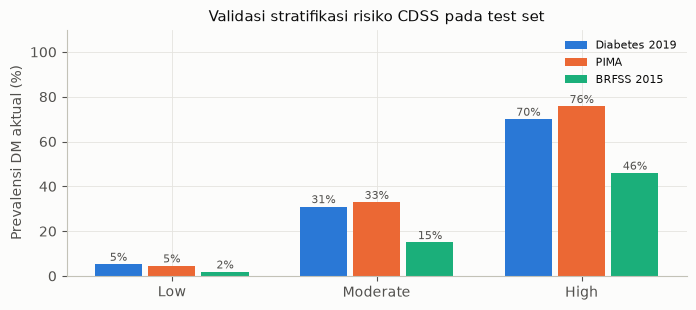

In [23]:
TIERS = {}
tier_rows = []
for k, out in RESULTS.items():
    s4 = out['R']['S4']; y_tr = SPECS[k].y.iloc[out['tr']].to_numpy(); y_te = SPECS[k].y.iloc[out['te']].to_numpy()
    t_low, t_high = tier_cutoffs(y_tr, s4.extras['oof_used'])
    TIERS[k] = (t_low, s4.thr, t_high)
    tier = np.where(s4.p_test >= t_high, 'High', np.where(s4.p_test >= t_low, 'Moderate', 'Low'))
    for t in ['Low', 'Moderate', 'High']:
        m = tier == t
        tier_rows.append({'Dataset': TITLE[k], 'Tingkat': t, 'n': int(m.sum()), '% pasien': m.mean() * 100,
                          'Prevalensi DM aktual': y_te[m].mean() if m.any() else np.nan,
                          '% seluruh kasus DM': y_te[m].sum() / y_te.sum() * 100,
                          'Rentang prob.': {'Low': f'< {t_low:.3f}', 'Moderate': f'{t_low:.3f}–{t_high:.3f}', 'High': f'≥ {t_high:.3f}'}[t]})
TIER_TABLE = pd.DataFrame(tier_rows); display(TIER_TABLE)
for k, (a, b, c) in TIERS.items():
    print(f'{TITLE[k]:>13}: t_low={a:.3f} | ambang operasional (F2)={b:.3f} | t_high={c:.3f}')

fig, ax = plt.subplots(figsize=(8, 3.2))
w = 0.26
for i, k in enumerate(SPECS):
    g = TIER_TABLE[TIER_TABLE['Dataset'] == TITLE[k]]
    ax.bar(np.arange(3) + (i - 1) * w, g['Prevalensi DM aktual'] * 100, width=w - 0.03, color=DS_COLOR[k], label=TITLE[k])
    for j, v in enumerate(g['Prevalensi DM aktual'] * 100):
        ax.text(j + (i - 1) * w, v + 1.5, f'{v:.0f}%', ha='center', fontsize=8, color=TEXT2)
ax.set_xticks(range(3)); ax.set_xticklabels(['Low', 'Moderate', 'High'])
ax.set(ylabel='Prevalensi DM aktual (%)', title='Validasi stratifikasi risiko CDSS pada test set', ylim=(0, 110))
ax.legend(fontsize=8)
savefig(fig, 'fig09_risk_tiers')

In [25]:
def export_cdss(name, title, s4, spec, tiers, tuning):
    """Ekspor artefak portabel: booster XGBoost (JSON) + konfigurasi inferensi (tanpa pickle kelas kustom)."""
    model = s4.extras['model']
    sel, imp, clf = model.named_steps['select'], model.named_steps['impute'], model.named_steps['clf']
    d = ART / name; d.mkdir(parents=True, exist_ok=True)
    clf.model_.save_model(d / 'model.json')
    t_low, t_op, t_high = tiers
    cfg = {'name': name, 'dataset': spec.key, 'title': title, 'created': time.strftime('%Y-%m-%d %H:%M'),
           'features_all': list(spec.X.columns), 'features_used': list(sel.selected_),
           'impute_median': {c: float(v) for c, v in imp.statistics_.items()},
           'encoding': {c: m for c, m in MAPS_2019.items()} if spec.key == 'diabetes2019' else {},
           'zero_as_nan': PIMA_ZERO_AS_NAN if spec.key == 'pima' else [],
           'calibrator': s4.extras['calibrator'].to_dict(), 'threshold_operating': t_op, 'tier_low': t_low, 'tier_high': t_high,
           'feature_meta': {c: META[spec.key][c] for c in spec.X.columns}, 'established_concepts': sorted(ESTABLISHED),
           'feature_range': {c: [float(spec.X[c].min()), float(spec.X[c].max())] for c in spec.X.columns},
           'test_metrics': {m: float(s4.test[m]) for m in MAIN}, 'scale_pos_weight': float(clf.scale_pos_weight_),
           'xgb_params': tuning['xgb_params'], 'sampling_strategy': tuning['sampling']}
    (d / 'config.json').write_text(json.dumps(cfg, indent=2, ensure_ascii=False), encoding='utf-8')
    print(f'Artefak CDSS "{title}" diekspor ke {d} ({len(cfg["features_used"])} input formulir)')
    return d

for k in SPECS:
    export_cdss(k, TITLE[k], RESULTS[k]['R']['S4'], SPECS[k], TIERS[k], RESULTS[k]['tuning']['S2'])

# Varian skrining Diabetes 2019 tanpa RegularMedicine (rekomendasi dari temuan SHAP, Bagian 10–11):
# untuk deteksi dini pada orang yang BELUM terdiagnosis, fitur "konsumsi obat rutin" berisiko menjadi jalan pintas.
_v = PROTO_RES[('diabetes2019', 'nomed')]
_y_tr_v = _v['spec'].y.iloc[_v['tr']].to_numpy(); _y_te_v = _v['spec'].y.iloc[_v['te']].to_numpy()
_tl, _th = tier_cutoffs(_y_tr_v, _v['S4'].extras['oof_used'])
TIERS['diabetes2019_screening'] = (_tl, _v['S4'].thr, _th)
export_cdss('diabetes2019_screening', 'Diabetes 2019 · varian skrining (tanpa RegularMedicine)', _v['S4'], _v['spec'],
            TIERS['diabetes2019_screening'], RESULTS['diabetes2019']['tuning']['S2'])
_tier = np.where(_v['S4'].p_test >= _th, 'High', np.where(_v['S4'].p_test >= _tl, 'Moderate', 'Low'))
SCREEN_TIERS = pd.DataFrame([{'Tingkat': t, 'n': int((_tier == t).sum()), '% pasien': (_tier == t).mean() * 100,
                              'Prevalensi DM aktual': _y_te_v[_tier == t].mean() if (_tier == t).any() else np.nan,
                              '% seluruh kasus DM': _y_te_v[_tier == t].sum() / _y_te_v.sum() * 100}
                             for t in ['Low', 'Moderate', 'High']])
print('Validasi tingkat risiko varian skrining Diabetes 2019 (test set):'); display(SCREEN_TIERS)


class CDSSEngine:
    """Mesin inferensi CDSS yang hanya membaca artefak ekspor (model.json + config.json)."""
    def __init__(self, art_dir):
        art_dir = Path(art_dir)
        self.cfg = json.loads((art_dir / 'config.json').read_text(encoding='utf-8'))
        self.model = xgb.XGBClassifier(); self.model.load_model(art_dir / 'model.json')
        self.explainer = shap.TreeExplainer(self.model)

    def _encode(self, patient):
        c = self.cfg; row = {}
        for f in c['features_all']:
            src = 'Gender' if f == 'Gender_Male' else f
            v = patient.get(f, patient.get(src, np.nan))
            if isinstance(v, str):
                v = c['encoding'][src][v.strip().lower()]
            row[f] = float(v) if v is not None else np.nan
        if c['dataset'] == 'diabetes2019' and row.get('Gender_Male') == 1:
            row['Pregancies'], row['Pdiabetes'] = 0.0, 0.0
        for f in c['zero_as_nan']:
            if row.get(f) == 0:
                row[f] = np.nan
        X = pd.DataFrame([row]).fillna(c['impute_median'])
        return X[c['features_used']].astype(float)

    def _calibrate(self, p):
        cal = self.cfg['calibrator']
        if cal['method'] == 'sigmoid':
            return float(1 / (1 + np.exp(-(cal['a'] * _logit(p) + cal['b']))))
        return float(np.interp(p, cal['x'], cal['y']))

    def predict(self, patient):
        X = self._encode(patient)
        p = self._calibrate(self.model.predict_proba(X)[0, 1])
        c = self.cfg
        tier = 'High' if p >= c['tier_high'] else ('Moderate' if p >= c['tier_low'] else 'Low')
        sv = self.explainer(X)[0]
        contrib = pd.DataFrame({'Fitur': X.columns, 'Label': [c['feature_meta'][f]['label'] for f in X.columns],
                                'Nilai': X.iloc[0].values, 'SHAP': sv.values}).sort_values('SHAP', key=np.abs, ascending=False)
        return {'risk': p, 'tier': tier, 'screen_positive': p >= c['threshold_operating'], 'contrib': contrib, 'explanation': sv, 'X': X}

    def report(self, patient, name='Pasien', plot=True):
        r = self.predict(patient); c = self.cfg
        rec = {'High': 'Rujuk untuk pemeriksaan konfirmasi (GDP/HbA1c/TTGO) dan konseling dokter.',
               'Moderate': 'Pemeriksaan glukosa terjadwal dan intervensi gaya hidup; evaluasi ulang berkala.',
               'Low': 'Skrining ulang rutin sesuai pedoman; pertahankan gaya hidup sehat.'}[r['tier']]
        print(f"[{c['title']}] {name}: risiko DM terkalibrasi = {r['risk']*100:.1f}% → tingkat {r['tier'].upper()} "
              f"({'skrining positif' if r['screen_positive'] else 'skrining negatif'} pada ambang {c['threshold_operating']:.3f})")
        print('  Rekomendasi:', rec)
        up = r['contrib'][r['contrib']['SHAP'] > 0].head(3); down = r['contrib'][r['contrib']['SHAP'] < 0].head(2)
        inv = {('Gender_Male' if s == 'Gender' else s): {v: kk for kk, v in m.items()} for s, m in c['encoding'].items()}
        show = lambda f, v: inv[f].get(int(v), v) if f in inv and float(v).is_integer() else f'{v:g}'
        print('  Faktor yang meningkatkan risiko :', '; '.join(f"{a} = {show(f, v)}" for f, a, v in zip(up['Fitur'], up['Label'], up['Nilai'])) or '-')
        print('  Faktor yang menurunkan risiko   :', '; '.join(f"{a} = {show(f, v)}" for f, a, v in zip(down['Fitur'], down['Label'], down['Nilai'])) or '-')
        acts = [c['feature_meta'][f]['advice'] for f in up['Fitur'] if c['feature_meta'][f]['advice']]
        print('  Saran yang dapat ditindaklanjuti:', ' '.join(dict.fromkeys(acts)) or 'tidak ada faktor modifiable yang dominan.')
        if plot:
            e = r['explanation']; e.feature_names = list(r['contrib'].set_index('Fitur').loc[r['X'].columns, 'Label'])
            plt.figure()
            shap.plots.waterfall(e, max_display=8, show=False)
            plt.title(f"{c['title']} · {name} · risiko {r['risk']*100:.1f}% ({r['tier']})", fontsize=10)
            savefig(plt.gcf(), f"fig10_cdss_{c['name']}_{name.replace(' ', '_')}")
        return r

ENGINES = {name: CDSSEngine(ART / name) for name in list(SPECS) + ['diabetes2019_screening']}
# Uji konsistensi: mesin CDSS (hanya membaca artefak) harus mereproduksi probabilitas S4 pada test set
_checks = {k: (RESULTS[k]['R']['S4'], SPECS[k].X.iloc[RESULTS[k]['te']]) for k in SPECS}
_checks['diabetes2019_screening'] = (_v['S4'], _v['spec'].X.iloc[_v['te']])
for name, (s4, X_te) in _checks.items():
    eng = ENGINES[name]
    Xt = transform_features(s4.extras['model'], X_te)
    p_eng = np.array([eng._calibrate(v) for v in eng.model.predict_proba(Xt)[:, 1]])
    print(f'{name:>22}: selisih maks. probabilitas CDSS vs S4 = {np.abs(p_eng - s4.p_test).max():.2e}')

Artefak CDSS "Diabetes 2019" diekspor ke outputs\cdss\diabetes2019 (10 input formulir)
Artefak CDSS "PIMA" diekspor ke outputs\cdss\pima (6 input formulir)
Artefak CDSS "BRFSS 2015" diekspor ke outputs\cdss\brfss (6 input formulir)
Artefak CDSS "Diabetes 2019 · varian skrining (tanpa RegularMedicine)" diekspor ke outputs\cdss\diabetes2019_screening (10 input formulir)
Validasi tingkat risiko varian skrining Diabetes 2019 (test set):


,Tingkat,n,% pasien,Prevalensi DM aktual,% seluruh kasus DM
0,Low,24,12.8342,0.0000,0.0000
1,Moderate,123,65.7754,0.2276,51.8519
2,High,40,21.3904,0.6500,48.1481


          diabetes2019: selisih maks. probabilitas CDSS vs S4 = 0.00e+00
                  pima: selisih maks. probabilitas CDSS vs S4 = 0.00e+00
                 brfss: selisih maks. probabilitas CDSS vs S4 = 0.00e+00
diabetes2019_screening: selisih maks. probabilitas CDSS vs S4 = 0.00e+00


[Diabetes 2019] Pasien A: risiko DM terkalibrasi = 28.9% → tingkat MODERATE (skrining positif pada ambang 0.163)
  Rekomendasi: Pemeriksaan glukosa terjadwal dan intervensi gaya hidup; evaluasi ulang berkala.
  Faktor yang meningkatkan risiko : Kelompok usia = 50-59; Kategori tekanan darah = high; Tingkat stres = very often
  Faktor yang menurunkan risiko   : Konsumsi obat rutin = no; Tidur nyenyak (jam) = 4
  Saran yang dapat ditindaklanjuti: Pantau tekanan darah secara berkala. Kelola stres (aktivitas fisik, tidur cukup, konseling bila perlu).


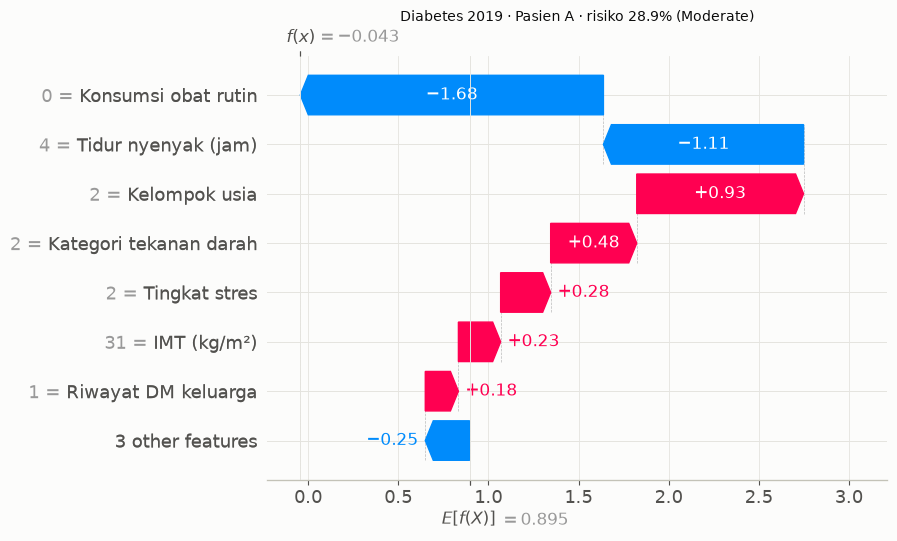


[Diabetes 2019] Pasien B: risiko DM terkalibrasi = 3.6% → tingkat LOW (skrining negatif pada ambang 0.163)
  Rekomendasi: Skrining ulang rutin sesuai pedoman; pertahankan gaya hidup sehat.
  Faktor yang meningkatkan risiko : Tidur nyenyak (jam) = 7; Aktivitas fisik harian = one hr or more
  Faktor yang menurunkan risiko   : Kelompok usia = less than 40; Konsumsi obat rutin = no
  Saran yang dapat ditindaklanjuti: Perbaiki kualitas tidur. Tingkatkan aktivitas fisik intensitas sedang secara bertahap.


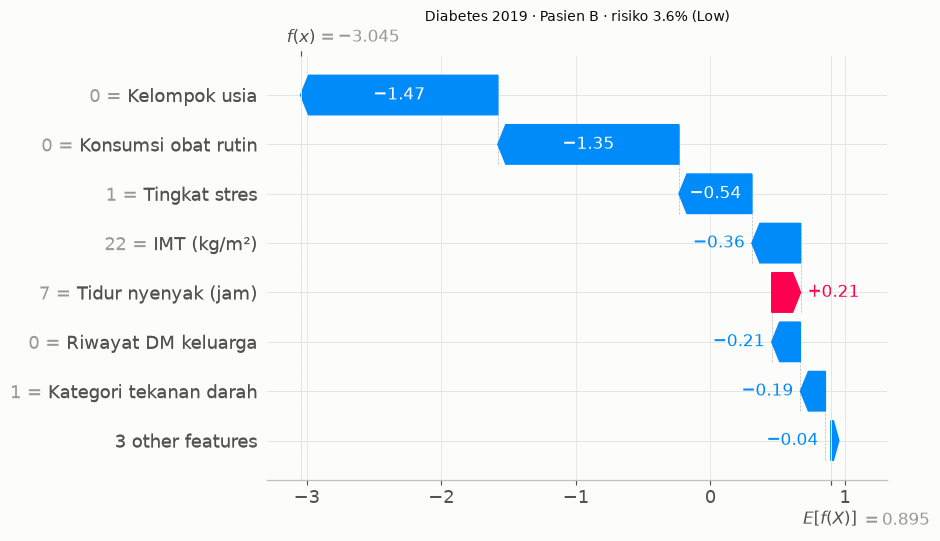


[Diabetes 2019 · varian skrining (tanpa RegularMedicine)] Pasien A: risiko DM terkalibrasi = 80.1% → tingkat HIGH (skrining positif pada ambang 0.166)
  Rekomendasi: Rujuk untuk pemeriksaan konfirmasi (GDP/HbA1c/TTGO) dan konseling dokter.
  Faktor yang meningkatkan risiko : Kelompok usia = 50-59; Riwayat DM keluarga = yes; Kategori tekanan darah = high
  Faktor yang menurunkan risiko   : Tidur nyenyak (jam) = 4; Durasi tidur (jam) = 6
  Saran yang dapat ditindaklanjuti: Pantau tekanan darah secara berkala.


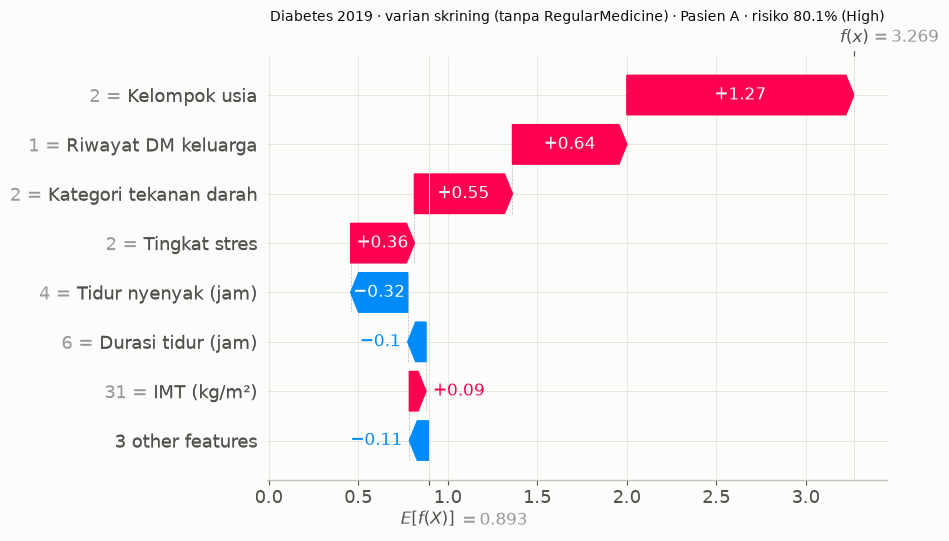


[Diabetes 2019 · varian skrining (tanpa RegularMedicine)] Pasien B: risiko DM terkalibrasi = 4.9% → tingkat LOW (skrining negatif pada ambang 0.166)
  Rekomendasi: Skrining ulang rutin sesuai pedoman; pertahankan gaya hidup sehat.
  Faktor yang meningkatkan risiko : Tidur nyenyak (jam) = 7
  Faktor yang menurunkan risiko   : Kelompok usia = less than 40; Tingkat stres = sometimes
  Saran yang dapat ditindaklanjuti: Perbaiki kualitas tidur.


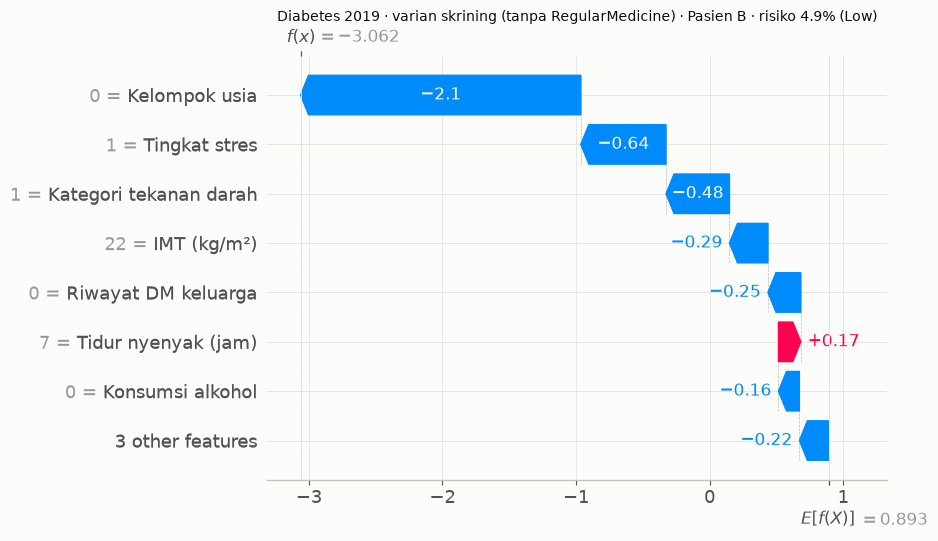


[PIMA] Pasien A: risiko DM terkalibrasi = 82.4% → tingkat HIGH (skrining positif pada ambang 0.205)
  Rekomendasi: Rujuk untuk pemeriksaan konfirmasi (GDP/HbA1c/TTGO) dan konseling dokter.
  Faktor yang meningkatkan risiko : Glukosa plasma 2 jam TTGO (mg/dL) = 168; Skor silsilah diabetes (DPF) = 0.85; IMT (kg/m²) = 36.5
  Faktor yang menurunkan risiko   : Jumlah kehamilan = 3
  Saran yang dapat ditindaklanjuti: Glukosa tinggi: konfirmasi dengan GDP/HbA1c dan perbaiki pola makan. Turunkan berat badan secara bertahap.


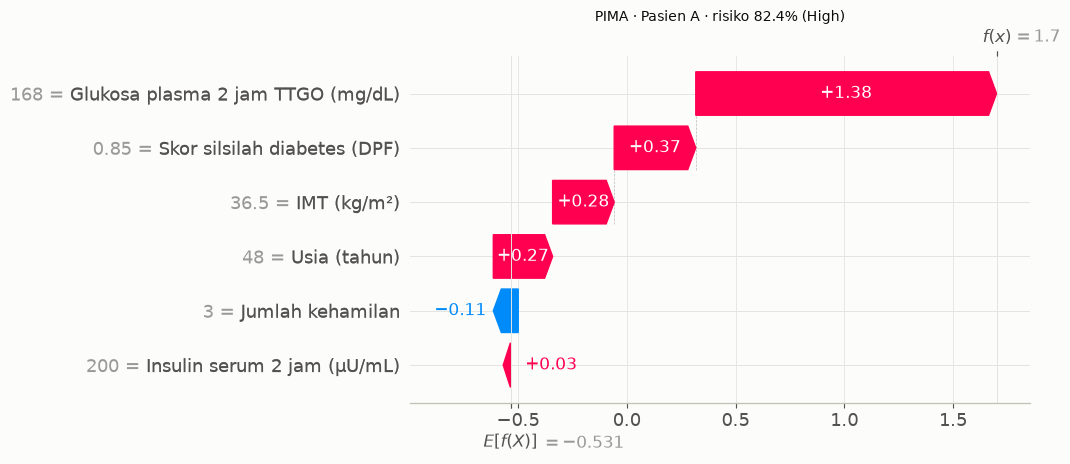


[PIMA] Pasien B: risiko DM terkalibrasi = 2.6% → tingkat LOW (skrining negatif pada ambang 0.205)
  Rekomendasi: Skrining ulang rutin sesuai pedoman; pertahankan gaya hidup sehat.
  Faktor yang meningkatkan risiko : -
  Faktor yang menurunkan risiko   : Glukosa plasma 2 jam TTGO (mg/dL) = 92; IMT (kg/m²) = 23.1
  Saran yang dapat ditindaklanjuti: tidak ada faktor modifiable yang dominan.


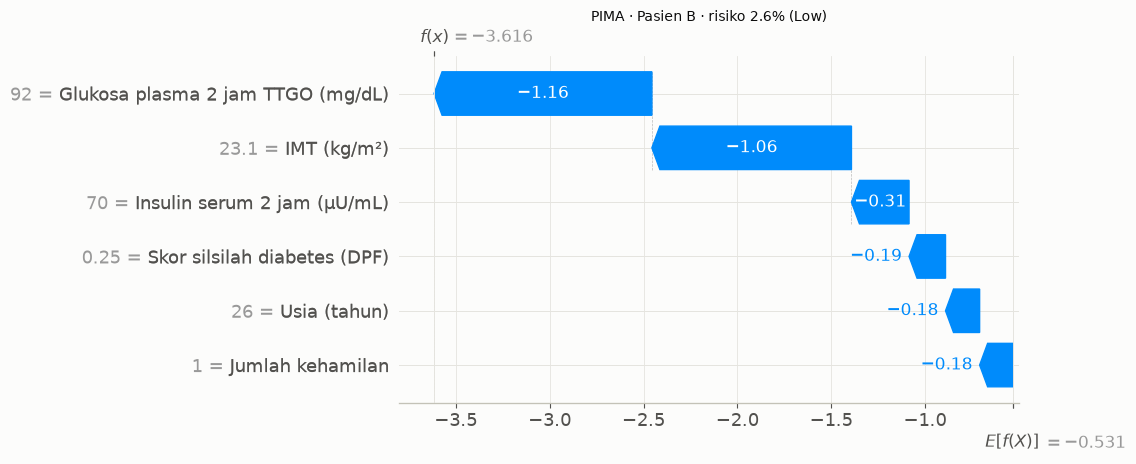


[BRFSS 2015] Pasien A: risiko DM terkalibrasi = 61.0% → tingkat HIGH (skrining positif pada ambang 0.122)
  Rekomendasi: Rujuk untuk pemeriksaan konfirmasi (GDP/HbA1c/TTGO) dan konseling dokter.
  Faktor yang meningkatkan risiko : Persepsi kesehatan umum (1–5) = 4; IMT (kg/m²) = 34; Hipertensi = 1
  Faktor yang menurunkan risiko   : -
  Saran yang dapat ditindaklanjuti: Turunkan berat badan secara bertahap. Kendalikan tekanan darah.


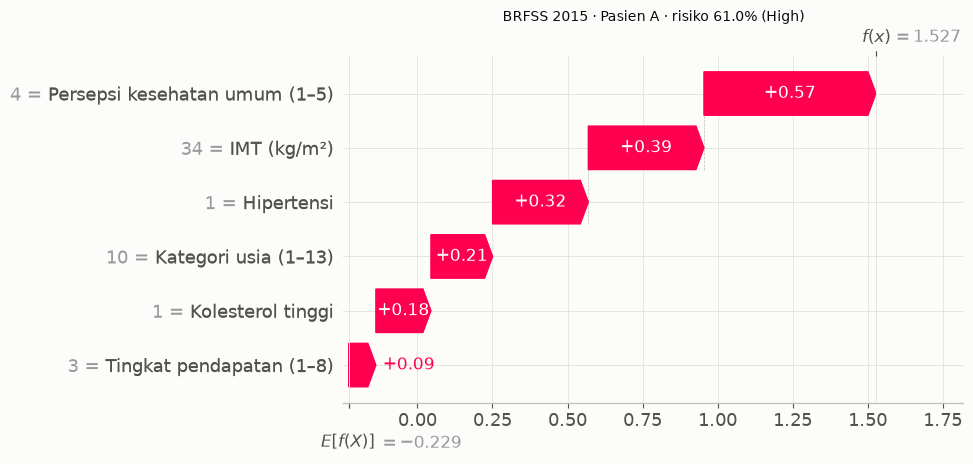


[BRFSS 2015] Pasien B: risiko DM terkalibrasi = 0.6% → tingkat LOW (skrining negatif pada ambang 0.122)
  Rekomendasi: Skrining ulang rutin sesuai pedoman; pertahankan gaya hidup sehat.
  Faktor yang meningkatkan risiko : -
  Faktor yang menurunkan risiko   : Kategori usia (1–13) = 4; Persepsi kesehatan umum (1–5) = 2
  Saran yang dapat ditindaklanjuti: tidak ada faktor modifiable yang dominan.


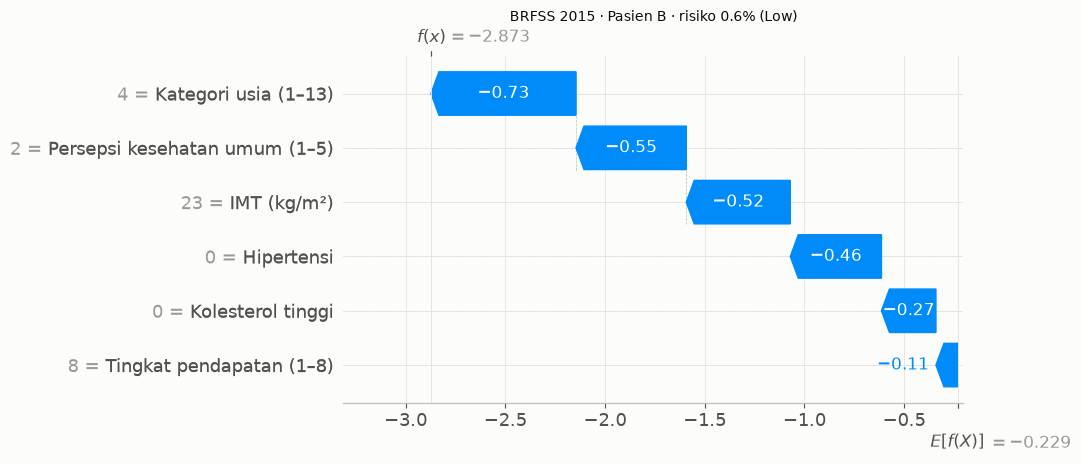

In [26]:
NEW_PATIENTS = {
    'diabetes2019': {
        'Pasien A': dict(Age='50-59', Gender='male', Family_Diabetes='yes', highBP='yes', PhysicallyActive='none', BMI=31, Smoking='no',
                         Alcohol='no', Sleep=6, SoundSleep=4, RegularMedicine='no', JunkFood='often', Stress='very often',
                         BPLevel='high', Pregancies=0, Pdiabetes='no', UriationFreq='quite often'),
        'Pasien B': dict(Age='less than 40', Gender='female', Family_Diabetes='no', highBP='no', PhysicallyActive='one hr or more', BMI=22,
                         Smoking='no', Alcohol='no', Sleep=8, SoundSleep=7, RegularMedicine='no', JunkFood='occasionally',
                         Stress='sometimes', BPLevel='normal', Pregancies=1, Pdiabetes='no', UriationFreq='not much')},
    'pima': {
        'Pasien A': dict(Pregnancies=3, Glucose=168, BloodPressure=82, SkinThickness=35, Insulin=200, BMI=36.5, DiabetesPedigreeFunction=0.85, Age=48),
        'Pasien B': dict(Pregnancies=1, Glucose=92, BloodPressure=70, SkinThickness=20, Insulin=70, BMI=23.1, DiabetesPedigreeFunction=0.25, Age=26)},
    'brfss': {
        'Pasien A': dict(HighBP=1, HighChol=1, CholCheck=1, BMI=34, Smoker=1, Stroke=0, HeartDiseaseorAttack=1, PhysActivity=0, Fruits=0,
                         Veggies=1, HvyAlcoholConsump=0, AnyHealthcare=1, NoDocbcCost=0, GenHlth=4, MentHlth=5, PhysHlth=15, DiffWalk=1,
                         Sex=1, Age=10, Education=4, Income=3),
        'Pasien B': dict(HighBP=0, HighChol=0, CholCheck=1, BMI=23, Smoker=0, Stroke=0, HeartDiseaseorAttack=0, PhysActivity=1, Fruits=1,
                         Veggies=1, HvyAlcoholConsump=0, AnyHealthcare=1, NoDocbcCost=0, GenHlth=2, MentHlth=0, PhysHlth=0, DiffWalk=0,
                         Sex=0, Age=4, Education=6, Income=8)},
}
SIM = {}
for k, pts in NEW_PATIENTS.items():
    for e in [k] + (['diabetes2019_screening'] if k == 'diabetes2019' else []):   # 2019: model utama vs varian skrining
        for name, pt in pts.items():
            SIM[(e, name)] = ENGINES[e].report(pt, name)
            print()

## 14. Ringkasan Uji Hipotesis H1–H4
Kriteria keputusan ditetapkan sebelum eksperimen penuh:
* **H1** — S2 vs S0: FNR turun (Wilcoxon per-*fold* p < 0,05) **dan** AUPRC naik pada test set, **dan** spesifisitas tidak turun "drastis" (≤ 10 poin persentase). Bila FNR turun signifikan tetapi spesifisitas turun > 10 poin, H1 dinilai *didukung sebagian*; Δ *balanced accuracy* (= rata-rata sensitivitas dan spesifisitas, tidak bergantung prevalensi) dilaporkan untuk menunjukkan apakah pertukaran sensitivitas–spesifisitas secara neto menguntungkan.
* **H2** — S3 vs S2: F1 test S3 ≥ F1 S2 − 0,01 (*non-inferiority* 1 poin) dengan fitur lebih sedikit; latensi dilaporkan.
* **H3** — S4 vs S3: Brier test lebih rendah dan CI95 bootstrap berpasangan untuk ΔBrier seluruhnya < 0.
* **H4** — kriteria pada Bagian 10.1.

In [27]:
def verdict(ok, partial=False):
    return 'Didukung' if ok else ('Didukung sebagian' if partial else 'Tidak didukung')

hyp_rows = []
for k, out in RESULTS.items():
    R = out['R']; s0, s2, s3, s4 = R['S0'].test, R['S2'].test, R['S3'].test, R['S4'].test
    w = WILCOX[(WILCOX['Dataset'] == TITLE[k]) & (WILCOX['Perbandingan'] == 'S2 vs S0')].set_index('Metrik')['p Wilcoxon']
    fnr_down, auprc_up = s2['FNR'] < s0['FNR'], s2['AUPRC'] > s0['AUPRC']
    spec_drop = s0['Specificity'] - s2['Specificity']
    d_bal = s2['BalancedAcc'] - s0['BalancedAcc']
    sig = w['FNR'] < 0.05
    hyp_rows.append({'Hipotesis': 'H1', 'Dataset': TITLE[k],
                     'Bukti': f"FNR {s0['FNR']:.3f}→{s2['FNR']:.3f} (p={w['FNR']:.3f}); AUPRC {s0['AUPRC']:.3f}→{s2['AUPRC']:.3f} (p={w['AUPRC']:.3f}); "
                              f"spesifisitas {s0['Specificity']:.3f}→{s2['Specificity']:.3f} ({-spec_drop*100:+.1f} poin); Δ balanced acc {d_bal:+.3f}",
                     'Keputusan': verdict(fnr_down and sig and auprc_up and spec_drop <= 0.10,
                                          partial=fnr_down and sig and (auprc_up or d_bal >= 0))})
    k3 = n_features(R['S3'], k); p_all = SPECS[k].X.shape[1]
    lat = LATENCY[LATENCY['Dataset'] == TITLE[k]].set_index('Skenario')['Latensi/pasien (ms)']
    hyp_rows.append({'Hipotesis': 'H2', 'Dataset': TITLE[k],
                     'Bukti': f"F1 {s2['F1']:.3f}→{s3['F1']:.3f}; fitur {p_all}→{k3}; latensi {lat['S2']:.2f}→{lat['S3']:.2f} ms",
                     'Keputusan': verdict(s3['F1'] >= s2['F1'] - 0.01 and k3 < p_all, partial=k3 < p_all and s3['F1'] >= s2['F1'] - 0.03)})
    b = BOOT[(k, 'S4 vs S3')].loc['Brier']
    hyp_rows.append({'Hipotesis': 'H3', 'Dataset': TITLE[k],
                     'Bukti': f"Brier {s3['Brier']:.4f}→{s4['Brier']:.4f} (Δ={b['Δ titik']:.4f}, CI95 [{b['CI95 bawah']:.4f}, {b['CI95 atas']:.4f}]); "
                              f"ECE {s3['ECE']:.3f}→{s4['ECE']:.3f}",
                     'Keputusan': verdict(s4['Brier'] < s3['Brier'] and b['CI95 atas'] < 0, partial=s4['Brier'] < s3['Brier'])})
    h4 = H4_TABLE.set_index('Dataset').loc[TITLE[k]]
    hyp_rows.append({'Hipotesis': 'H4', 'Dataset': TITLE[k],
                     'Bukti': f"{h4['Top-5 global yang faktor risiko mapan']}/5 top global mapan; keselarasan lokal {h4['Rasio keselarasan lokal top-3']*100:.0f}%",
                     'Keputusan': verdict(h4['Top-5 global yang faktor risiko mapan'] >= 3 and h4['Rasio keselarasan lokal top-3'] >= 0.60,
                                          partial=h4['Top-5 global yang faktor risiko mapan'] >= 3 or h4['Rasio keselarasan lokal top-3'] >= 0.60)})
HYPOTHESES = pd.DataFrame(hyp_rows)
with pd.option_context('display.max_colwidth', 200):
    display(HYPOTHESES)
HYPOTHESES.to_csv(OUT / 'hypotheses.csv', index=False)

,Hipotesis,Dataset,Bukti,Keputusan
0,H1,Diabetes 2019,FNR 0.444→0.315 (p=0.125); AUPRC 0.719→0.689 (p=0.193); spesifisitas 0.895→0.857 (-3.8 poin); Δ balanced acc +0.046,Tidak didukung
1,H2,Diabetes 2019,F1 0.673→0.729; fitur 17→10; latensi 4.84→4.36 ms,Didukung
2,H3,Diabetes 2019,"Brier 0.1393→0.1433 (Δ=0.0040, CI95 [-0.0305, 0.0366]); ECE 0.122→0.104",Tidak didukung
3,H4,Diabetes 2019,2/5 top global mapan; keselarasan lokal 58%,Tidak didukung
4,H1,PIMA,FNR 0.407→0.074 (p=0.002); AUPRC 0.674→0.776 (p=0.010); spesifisitas 0.820→0.460 (-36.0 poin); Δ balanced acc -0.013,Didukung sebagian
5,H2,PIMA,F1 0.633→0.653; fitur 8→6; latensi 2.41→2.87 ms,Didukung
6,H3,PIMA,"Brier 0.1524→0.1515 (Δ=-0.0009, CI95 [-0.0037, 0.0017]); ECE 0.069→0.049",Didukung sebagian
7,H4,PIMA,5/5 top global mapan; keselarasan lokal 92%,Didukung
8,H1,BRFSS 2015,FNR 0.806→0.160 (p=0.002); AUPRC 0.440→0.440 (p=1.000); spesifisitas 0.976→0.662 (-31.3 poin); Δ balanced acc +0.166,Didukung sebagian
9,H2,BRFSS 2015,F1 0.433→0.430; fitur 21→6; latensi 5.07→5.48 ms,Didukung


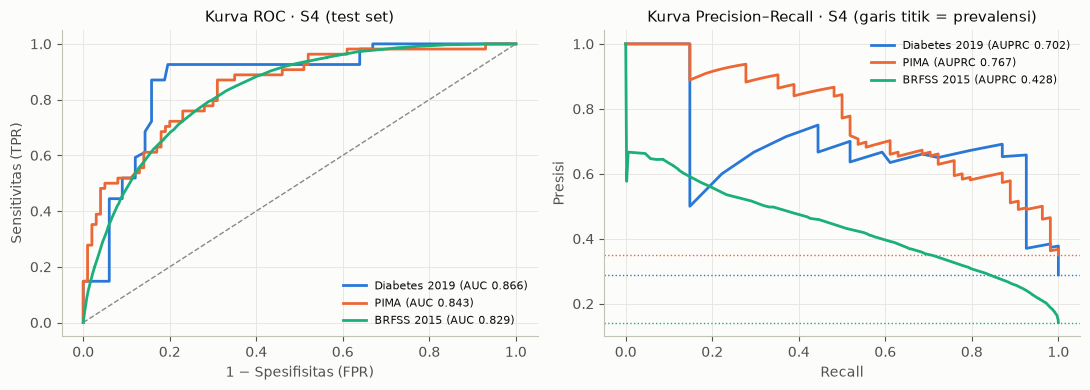

Selesai. Total waktu eksekusi: 22.8 menit. Semua tabel/figur tersimpan di D:\KA\New Project\Models\outputs


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for k, out in RESULTS.items():
    y_te = SPECS[k].y.iloc[out['te']]; p = out['R']['S4'].p_test
    fpr, tpr, _ = roc_curve(y_te, p); pr, rc, _ = precision_recall_curve(y_te, p)
    axes[0].plot(fpr, tpr, color=DS_COLOR[k], label=f"{TITLE[k]} (AUC {roc_auc_score(y_te, p):.3f})")
    axes[1].plot(rc, pr, color=DS_COLOR[k], label=f"{TITLE[k]} (AUPRC {average_precision_score(y_te, p):.3f})")
    axes[1].axhline(y_te.mean(), ls=':', lw=1, color=DS_COLOR[k])
axes[0].plot([0, 1], [0, 1], ls='--', lw=1, color='#8a8984')
axes[0].set(xlabel='1 − Spesifisitas (FPR)', ylabel='Sensitivitas (TPR)', title='Kurva ROC · S4 (test set)')
axes[1].set(xlabel='Recall', ylabel='Presisi', title='Kurva Precision–Recall · S4 (garis titik = prevalensi)')
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
savefig(fig, 'fig11_roc_pr')

summary = {
    'runtime_minutes': (time.time() - T_START) / 60, 'fast_mode': FAST_MODE, 'n_folds': N_FOLDS,
    'versions': {'xgboost': xgb.__version__, 'shap': shap.__version__, 'optuna': optuna.__version__,
                 'imblearn': imblearn.__version__, 'sklearn': sklearn.__version__},
    'data': DATA_SUMMARY.assign(**{'Sisa NaN (diimputasi di pipeline)': DATA_SUMMARY['Sisa NaN (diimputasi di pipeline)'].astype(str)}).to_dict('records'),
    'period_2019': PERIOD_2019,
    'tuning': {TITLE[k]: {s: {kk: vv for kk, vv in v.items()} for s, v in out['tuning'].items()} for k, out in RESULTS.items()},
    'calibration': {TITLE[k]: {'method': out['cal_method'], 'cv_brier': out['cal_briers_cv']} for k, out in RESULTS.items()},
    'tiers': {TITLE.get(k, k): {'t_low': a, 't_operating': b, 't_high': c} for k, (a, b, c) in TIERS.items()},
    'selection': SELECTION.to_dict('records'),
}
(OUT / 'summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=float), encoding='utf-8')
for name, df in [('leakage_audit', LEAKAGE_AUDIT), ('threshold_effect', THR_EFFECT), ('wilcoxon', WILCOX), ('calibration', CALIB_TABLE),
                 ('selection', SELECTION), ('latency', LATENCY), ('global_shap', GLOBAL_SHAP), ('h4_local', H4_TABLE),
                 ('risk_tiers', TIER_TABLE), ('data_summary', DATA_SUMMARY)]:
    df.to_csv(OUT / f'{name}.csv', index=False)
print(f'Selesai. Total waktu eksekusi: {(time.time() - T_START) / 60:.1f} menit. Semua tabel/figur tersimpan di {OUT.resolve()}')